# Predicting how a UFC fight ends
**Full Colab project · Decision, KO/TKO, or submission**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mauLanarhodes/4397-UFC-Method-Of-Victory/blob/main/two_stage_predictor.ipynb)

**Run in Colab.** Open the notebook, connect a CPU runtime, and choose **Runtime → Run all**. The code is in the cells below. The notebook downloads the committed data into its workspace, installs the experiment dependencies separately from the kernel, and saves new models, plots, and predictions. There is no repository clone or manual upload for the example.

- **`project`** (default) rebuilds the fight tables and refits the current direct and two-stage models. The older experiments are shown using their published results.
- **`full`** also refits the original multimodal study and the full-season accuracy sweep. Those sections run hundreds of model fits and take substantially longer on a CPU.
- **`preview`** recreates the plots from the committed results and runs the saved two-stage model on the example card. It is useful for reviewing the project quickly.
- The data collection tools and original serialized model replay are in the final section. They run only when enabled.

The original course project credits Ryan Rassoli, Samuel Balogun, Shourya Sai Macha, and Andrew Amadasu.

The original experiments compare inputs and model families using **macro F1**, which computes F1 separately for each outcome and weights the three outcomes equally. **Accuracy** measures the share of all picks that were correct. We report both because a model can score well on accuracy by calling many fights decisions and rarely finding submissions.

## 1. Set up the environment and load the data

The first cell creates a fresh directory for each run, so new results stay separate from existing runs. It installs pinned scientific packages for the training subprocesses. CPU versions of the boosters are sufficient for these datasets.

The second cell downloads input CSVs from a fixed commit of the fork. It verifies each file against its SHA-256 checksum and reuses matching downloads on later runs. The feature builders, training scripts, evaluation, and prediction code are written by the notebook cells themselves. Each **Source** cell contains the actual project code and writes a local module into the current run so standard imports and saved-model loading work.

In [1]:
import csv
import hashlib
import html
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import shutil
import subprocess
import sys
from tempfile import mkdtemp
from time import perf_counter, sleep
from urllib.parse import quote
from urllib.request import Request, urlopen

from IPython.display import HTML, Image, display

# "project" refits the current predictor. "full" also refits the older benchmarks.
RUN_MODE = "project"  # @param ["project", "full", "preview"]
if RUN_MODE not in {"project", "full", "preview"}:
    raise ValueError("Choose 'project', 'full', or 'preview'.")
FULL = RUN_MODE == "full"
REFIT = RUN_MODE != "preview"

WORKSPACE = Path(os.environ.get("UFC_NOTEBOOK_WORKSPACE", Path.cwd() / "ufc_colab")).expanduser().resolve()
WORKSPACE.mkdir(parents=True, exist_ok=True)
PROJECT = Path(mkdtemp(prefix="run-", dir=WORKSPACE))
PUBLISHED = WORKSPACE / "snapshot-a62eb62"
PUBLISHED.mkdir(exist_ok=True)
for relative in ["data", "models", "personal_test_set", "prepared", "results", "figures", "logs"]:
    (PROJECT / relative).mkdir()

# Keep package changes outside the Colab kernel. All project code runs on the CPU.
PINS = [
    "numpy==2.3.5", "pandas==2.2.3", "scipy==1.17.0", "scikit-learn==1.8.0",
    "joblib==1.5.3", "matplotlib==3.10.8", "catboost==1.2.10", "lightgbm==4.7.0",
    "xgboost-cpu==3.4.1", "requests>=2.31,<3", "beautifulsoup4>=4.12,<5",
]

def install_packages(requirements, *, base=None):
    key = hashlib.sha256((sys.version + "\n".join(requirements)).encode()).hexdigest()[:12]
    target = WORKSPACE / "packages" / key
    flag = target / ".complete"
    if not flag.exists():
        target.mkdir(parents=True, exist_ok=True)
        args = [sys.executable, "-m", "pip", "install", "--quiet", "--no-input",
                "--disable-pip-version-check", "--only-binary=:all:", "--upgrade",
                "--target", str(target), *requirements]
        print(f"Installing packages in an isolated directory ({key}) …", flush=True)
        subprocess.run(args, check=True)
        flag.touch()
    return os.pathsep.join([str(target), base]) if base else str(target)

PACKAGE_PATH = install_packages(PINS)
ENV = {
    **os.environ, "PYTHONPATH": PACKAGE_PATH, "PYTHONNOUSERSITE": "1",
    "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1", "OMP_NUM_THREADS": "2",
    "MPLBACKEND": "Agg", "MPLCONFIGDIR": str(WORKSPACE / "matplotlib-cache"),
}

def run_python(*args, name, package_path=None, cwd=PROJECT, tail=6):
    """Run a source cell's script in isolation and retain its full log."""
    log = PROJECT / "logs" / (name + ".txt")
    env = ENV.copy()
    if package_path is not None:
        env["PYTHONPATH"] = package_path
    print(f"{name} …", flush=True)
    start = perf_counter()
    with log.open("w", encoding="utf-8") as handle:
        child = subprocess.run([sys.executable, "-S", "-u", *map(str, args)], cwd=cwd,
                               env=env, stdout=handle, stderr=subprocess.STDOUT)
    lines = log.read_text(encoding="utf-8", errors="replace").splitlines()
    if child.returncode:
        raise RuntimeError(f"{name} failed. Log: {log}\n" + "\n".join(lines[-35:]))
    print(f"Finished in {perf_counter() - start:.1f} seconds.")
    if tail:
        print("\n".join(lines[-tail:]))

def show_csv(path, *, columns=None, limit=20):
    with Path(path).open(newline="", encoding="utf-8") as handle:
        reader = csv.DictReader(handle)
        keys = columns or reader.fieldnames
        rows = list(reader)
    def td(tag, value):
        return f"<{tag}>{html.escape(str(value))}</{tag}>"
    heading = "<tr>" + "".join(td("th", key) for key in keys) + "</tr>"
    body = ["<tr>" + "".join(td("td", row[key]) for key in keys) + "</tr>" for row in rows[:limit]]
    display(HTML(f"<table><thead>{heading}</thead><tbody>{''.join(body)}</tbody></table>"))
    if len(rows) > limit:
        print(f"Showing {limit} of {len(rows):,} rows. See {Path(path).name} for the full table.")

def show_chart(name):
    display(Image(filename=str(PROJECT / "figures" / f"{name}.png")))

print(f"Notebook workspace: {PROJECT}")

Notebook workspace: <current run>


In [2]:
DATA_FILES = ['data/data.csv',
 'data/raw_total_fight_data.csv',
 'data/raw_fighter_details.csv',
 'data/fighter_profiles.csv',
 'raw_fights_greco.csv',
 'fighter_details_greco.csv',
 'fights.csv',
 'raw_fights.csv',
 'fighter_details.csv',
 'fights_2025.csv',
 'target_fights.csv',
 'personal_test_set/labels.csv',
 'personal_test_set/meta.csv']
RESULT_FILES = ['results/ablation.csv',
 'results/confusion_test.csv',
 'results/era_experiment.csv',
 'results/family_importance.csv',
 'results/feature_importance_all.csv',
 'results/model_comparison.csv',
 'results/pruning.csv',
 'results/text_coverage.csv',
 'results/top_features.csv',
 'personal_ablation.csv',
 'personal_predictions.csv',
 'results/accuracy/selected_model.joblib',
 'results/accuracy/scores.csv',
 'results/accuracy/predictions_2025.csv',
 'results/accuracy/original_2025.csv',
 'results/method_rates/selected_model.joblib',
 'results/method_rates/scores.csv',
 'results/method_rates/picks_2025.csv',
 'results/method_rates/picks_2026.csv']
ASSETS = {'data/data.csv': 'a2dc0f77fafa05a10d701ecdc1f0318e454474651349c0afd8d985f2ef4c6984',
 'data/raw_total_fight_data.csv': 'f0b9565fe2baf52b5586df1ff0b2d24a56ad76fecaa74d49d073f4a43db7df99',
 'data/raw_fighter_details.csv': 'fb83c27be0d799fd4a2fede2e6465e3870de8e0c1fa8be4b7b0997bfc3e00ee4',
 'data/fighter_profiles.csv': '92817f2dc63e192f50a09c9ace41a38937b952216a6cfd3cc7918cd765ad0da4',
 'raw_fights_greco.csv': '0626b7a14d49464eebd81582e39f03af78691005574805413b41df1a488abd71',
 'fighter_details_greco.csv': '9f376b39616f1c9357d05686cc9c228cfd4bdb0fcc3efac04fc29b3507170cd4',
 'fights.csv': '01e63a970728ae473a2f8269309875f9f811890f2a55e7569e763d3b42b43d54',
 'raw_fights.csv': 'ecae592329e548dc59b1b1b0835756757e3df87de47861693e9049af99f2fd21',
 'fighter_details.csv': 'f725c3ed8ee5412b197a2a20bfe746227b52f45d6987045ad9cc60c8c19fe1e9',
 'fights_2025.csv': '3c8c3b4acd06643d7985fc8a00b4c46e54416dd55b31481f62ce44a1bff94896',
 'target_fights.csv': 'f1cde412448bca1f9eca756a823e27262f9f4a1d7087eefd5703c52fcb41634f',
 'personal_test_set/labels.csv': 'da90904d75f21c564c6bb120bacb5299348ef66d74f5000ea52d9f77a264d1f6',
 'personal_test_set/meta.csv': '4ab6d1c479b8ee7b1adcca49c9ffd8140dcc33651c80e8b67e1341327625e2d3',
 'results/ablation.csv': '6c2689ad8e883c56dc7d627e3c5c0ad4d6e330235941c391ac9126b20d6a88e5',
 'results/confusion_test.csv': '04ea3d89853fa850ff99f186aae687f2a0f1c83b27d4621af07d01752548af8b',
 'results/era_experiment.csv': '9aae345515d64e643bcc6c06a09db4dc33bb0395517a783956b9149ff94b910c',
 'results/family_importance.csv': '94991e2a18c4abdd51618312beb88c8ceb29eee194c97772c68764c59ba95bc1',
 'results/feature_importance_all.csv': 'ce340693bda2d5a50df1cc675026316f5ef79ee3e30eeb0f8a33c6100c6c5f33',
 'results/model_comparison.csv': '46896ce98a735d277d5fcc6dab2179a3bbe26f98fedbf636121d1a4d7eb0bf5e',
 'results/pruning.csv': '0674aad5eba88b3b676c0329b6617ca9cc0519d5e1aa8945a6f8639d745aa66a',
 'results/text_coverage.csv': '618dc748d3bc34e7741e0c4c2635f162331ecbfaa8109c90c03afb4fb181830c',
 'results/top_features.csv': '90fdaeaec18f100f5dcdf28fd4fb0bbf44cefadda3307126df578131ec830154',
 'personal_ablation.csv': 'f35e3edea6eb8937cb420492c8157c6be3fafd791f41864faeadd2acb283998c',
 'personal_predictions.csv': '9e30379a7b19a37eb5a3929142018cdc44c866e96d610fe4cac0f874169fadbd',
 'results/accuracy/selected_model.joblib': '276da26317afe5e774641345cbd5411e9f7096f2c997d440e49b1e8130625a59',
 'results/accuracy/scores.csv': '8f93c75f9fedc281fc5419c4bd3aebcd940214a4690715333db062824cc22db9',
 'results/accuracy/predictions_2025.csv': '9df54a4655404942438762a6fd78f4755b89c2b5c8d4907cf019d30caf308f4b',
 'results/accuracy/original_2025.csv': '93656d5f82261ce757edbd2f72c2377365c8c7841694de48f5ef4fa564450ef6',
 'results/method_rates/selected_model.joblib': '4d94f52a3341e486e6f13da6bd44cdd01aa54e19108f4b01b72a4ddd1f84bf83',
 'results/method_rates/scores.csv': '3ca8a99ec0a62a303c082ed041210cb5a76cf71ace4ec771749594a4ebade6db',
 'results/method_rates/picks_2025.csv': '3a7379bf9cfdd1b41e2a9d258f200e1cda82b00b4aef03fae39065b39e931c3f',
 'results/method_rates/picks_2026.csv': '4e3a4db96969c35e9fa683b8d8a63952ec8821b4b26db0adb2be7b3ae6f947e2',
 'final_model.joblib': '0c40a3cb496dd6b0d66470faf0afc8da79c231b761f3e6de9c05d41980606de5'}
# Keep the published CatBoost comparator fixed across run modes.
BASELINE_ASSET = 'results/accuracy/selected_model.joblib'
REQUIRED_ASSETS = DATA_FILES + ([BASELINE_ASSET] if FULL else RESULT_FILES)

FORK = "mauLanarhodes/4397-UFC-Method-Of-Victory"
REVISION = "a62eb623f1ddc81a7d9a300939550369f9299276"
RAW_URL = f"https://raw.githubusercontent.com/{FORK}/{REVISION}/"

def fetch_asset(relative):
    """Cache the exact committed bytes. A failed download never replaces the cache."""
    digest = ASSETS[relative]
    dest = PUBLISHED / relative
    if dest.is_file() and hashlib.sha256(dest.read_bytes()).hexdigest() == digest:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    request = Request(RAW_URL + quote(relative), headers={"User-Agent": "UFC-Colab-Notebook"})
    for attempt in range(3):
        try:
            with urlopen(request, timeout=30) as response:
                data = response.read()
            if hashlib.sha256(data).hexdigest() != digest:
                raise ValueError(f"Checksum mismatch for {relative}")
            staged = dest.with_suffix(dest.suffix + ".partial")
            staged.write_bytes(data)
            staged.replace(dest)
            return dest
        except (OSError, ValueError) as error:
            if attempt == 2:
                raise RuntimeError(f"Could not fetch {relative} from {RAW_URL}") from error
            sleep(2 ** attempt)

with ThreadPoolExecutor(max_workers=5) as pool:
    snapshots = list(pool.map(fetch_asset, REQUIRED_ASSETS))
print(f"Verified {len(snapshots)} data and benchmark files from {REVISION[:7]}.")

def copy_asset(relative, destination=None):
    dest = PROJECT / (destination or relative)
    dest.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(PUBLISHED / relative, dest)

for relative in DATA_FILES:
    copy_asset(relative)
copy_asset("personal_test_set/labels.csv", "labels.csv")
copy_asset("data/fighter_profiles.csv", "fighter_profiles.csv")

# Preview mode uses the checked-in benchmarks. The full run calculates new ones.
if not FULL:
    for relative in RESULT_FILES:
        copy_asset(relative, {"personal_ablation.csv": "results/personal_ablation.csv",
                              "personal_predictions.csv": "results/personal_predictions.csv"}.get(relative))

Verified 32 data and benchmark files from a62eb62.


## 2. Prepare and examine the fight data

| Input | Role in the project |
|---|---|
| Kaggle UFC data through March 2021 | Pre-fight measurements and statistics, plus bout outcomes to build labels and recent history |
| Fighter profiles from Wikipedia and UFC.com | Text for the original multimodal experiments |
| Committed Greco1899 UFCStats export | Raw records for rebuilding features and evaluating the 2025–2026 fights |
| Personal test set and upload example | Twenty bouts from UFC 317 and UFC 320 with labels for checking predictions |

The two data workflows share a label mapping. Decisions by any judging method become **DEC**, KO and doctor's stoppage become **KO/TKO**, and submissions become **SUB**. Bouts with outcomes outside these classes or without a winner are excluded from supervised training.

**Source · label alignment and recent history.** The next cell checks that the raw and prepared Kaggle rows describe the same bouts in the same order. The history builder picks up to five earlier contests for each fighter. It uses a strict date cutoff so another bout on the same day contributes no information.

In [3]:
%%writefile "{PROJECT}/build_dataset.py"
"""
build_dataset.py — join labels and build the tabular + fight-history modalities.

Inputs (Kaggle rajeevw/ufcdata, in data/):
  data.csv                  pre-fight stats per fight (R_ = red corner, B_ = blue corner)
  raw_total_fight_data.csv  fight-by-fight results incl. win_by (semicolon-separated)

Output: data/fights.csv — one row per fight with
  label (KO/TKO, SUB, DEC), date, tabular features, history features (h_ prefix)

Usage: python build_dataset.py
"""
import numpy as np
import pandas as pd

DATA = "data/"
N_HIST = 5  # how many previous fights the history modality looks at

LABEL_MAP = {
    "KO/TKO": "KO/TKO",
    "TKO - Doctor's Stoppage": "KO/TKO",
    "Submission": "SUB",
    "Decision - Unanimous": "DEC",
    "Decision - Split": "DEC",
    "Decision - Majority": "DEC",
}


def method_group(win_by):
    return LABEL_MAP.get(win_by)  # None for DQ, overturned, etc.


def load():
    d = pd.read_csv(DATA + "data.csv").copy()
    r =pd.read_csv(DATA + "raw_total_fight_data.csv", sep=";")
    r["date"] = pd.to_datetime(r["date"], format="mixed")
    d["date"] = pd.to_datetime(d["date"])
    # The two files list the same fights in the same order; check, then join by position.
    assert (d.R_fighter.values == r.R_fighter.values).all()
    assert (d.B_fighter.values == r.B_fighter.values).all()
    assert (d.date.values == r.date.values).all()
    d["win_by"] = r["win_by"].values
    d["last_round"] = r["last_round"].values  # outcome info: used only for history, never as a feature
    # scheduled rounds (3 or 5), known before the fight, e.g. "3 Rnd (5-5-5)" -> 3
    d["no_of_rounds"] = r["Format"].str.extract(r"^(\d+)")[0].astype(float).values
    d["raw_winner"] = r["Winner"].values  # winner's name; NaN for draws / no contests
    return d


# --------------------------------------------------------------- history modality
def history_features(d):
    """For each fight and corner, summarize that fighter's previous N_HIST fights.
    Built only from fights strictly before the current date (no leakage)."""
    # one row per (fighter, fight)
    rows = []
    for i, f in d.iterrows():
        for corner, opp in (("R", "B"), ("B", "R")):
            name = f[f"{corner}_fighter"]
            won = f["raw_winner"] == name
            lost = isinstance(f["raw_winner"], str) and not won
            m = method_group(f["win_by"])
            rows.append({
                "fight_idx": i, "corner": corner, "fighter": name, "date": f["date"],
                "won": won, "lost": lost, "method": m, "rounds": f["last_round"],
            })
    long = pd.DataFrame(rows).sort_values(["fighter", "date"])

    feats = {}
    for name, g in long.groupby("fighter", sort=False):
        g = g.reset_index(drop=True)
        dates = g.date.to_numpy()
        for k in range(len(g)):
            end = dates.searchsorted(dates[k], side="left")
            prev = g.iloc[max(0, end - N_HIST):end]
            cur = g.iloc[k]
            n = len(prev)
            out = {"h_n_prev": n}
            if n:
                out.update({
                    "h_win_rate": prev.won.mean(),
                    "h_win_ko": (prev.won & (prev.method == "KO/TKO")).mean(),
                    "h_win_sub": (prev.won & (prev.method == "SUB")).mean(),
                    "h_win_dec": (prev.won & (prev.method == "DEC")).mean(),
                    "h_loss_ko": (prev.lost & (prev.method == "KO/TKO")).mean(),
                    "h_loss_sub": (prev.lost & (prev.method == "SUB")).mean(),
                    "h_finish_rate": prev.method.isin(["KO/TKO", "SUB"]).mean(),
                    "h_avg_rounds": prev.rounds.mean(),
                    "h_days_since": (cur.date - prev.date.iloc[-1]).days,
                    "h_last_won": float(prev.won.iloc[-1]),
                })
            feats[(cur.fight_idx, cur.corner)] = out

    cols = ["h_n_prev", "h_win_rate", "h_win_ko", "h_win_sub", "h_win_dec", "h_loss_ko",
            "h_loss_sub", "h_finish_rate", "h_avg_rounds", "h_days_since", "h_last_won"]
    H = pd.DataFrame(index=d.index)
    for corner in ("R", "B"):
        block = pd.DataFrame([feats[(i, corner)] for i in d.index], index=d.index).reindex(columns=cols)
        block.columns = [f"{corner}_{c}" for c in cols]
        H = H.join(block)
    return H


def main():
    d = load()
    H = history_features(d)
    d = d.join(H)
    d["label"] = d["win_by"].map(method_group)
    d = d[d["label"].notna() & d["raw_winner"].notna()]  # drop DQs, overturned, draws, NCs
    d = d.drop(columns=["raw_winner"])
    d.to_csv(DATA + "fights.csv", index=False)
    print(f"Saved {len(d)} fights -> {DATA}fights.csv")
    print(d["label"].value_counts().to_string())


if __name__ == "__main__":
    main()

Writing <current run>/build_dataset.py


**Source · cumulative pre-fight statistics.** The raw UFCStats export records actions such as landed and attempted strikes as strings. This code parses those fields, converts time to seconds, and rebuilds each fighter's past averages and record. An exponentially weighted mean emphasizes recent fights, and debuts have no prior averages.

In [4]:
%%writefile "{PROJECT}/ufc_features.py"
"""
ufc_features.py — rebuild the Kaggle data.csv features from raw fight data.

This re-implements the feature math of the original dataset (rajeevw/ufcdata,
github.com/WarrierRajeev/UFC-Predictions, src/createdata/preprocess*.py) so that
NEW fights (our 2025 personal test set) get stats computed exactly the same way
as the training data. Key details copied from the original:

  * "avg" stats are exponentially weighted means over the fighter's PREVIOUS fights,
    oldest to newest: pandas .ewm(span=3, adjust=False).mean(), last value.
    So recent fights count more than old ones.
  * Records/streaks count draws as losses, and streaks are counted over a reversed
    fight list (both quirks of the original code, kept for consistency).
  * win_by counts sum the fighter's previous wins by each method.
  * Age = floor((fight date - DOB) / 365.25 days).

verify() checks the re-implementation against the Kaggle data.csv.

Usage: python ufc_features.py      (runs the check)
"""
import math
import re

import numpy as np
import pandas as pd

SPLIT_COLS = ["SIG_STR.", "TOTAL_STR.", "TD", "HEAD", "BODY", "LEG", "DISTANCE", "CLINCH", "GROUND"]
WIN_BY = ["Decision - Majority", "Decision - Split", "Decision - Unanimous", "KO/TKO",
          "Submission", "TKO - Doctor's Stoppage"]
NUM = ["KD", "SIG_STR_pct", "TD_pct", "SUB_ATT", "REV"]
FIRST_ROUND_SECONDS = {
    "3 Rnd (5-5-5)": 300, "5 Rnd (5-5-5-5-5)": 300, "1 Rnd + OT (12-3)": 720, "No Time Limit": 1,
    "3 Rnd + OT (5-5-5-5)": 300, "1 Rnd (20)": 20, "2 Rnd (5-5)": 300, "1 Rnd (15)": 900,
    "1 Rnd (10)": 600, "1 Rnd (12)": 720, "1 Rnd + OT (30-5)": 1800, "1 Rnd (18)": 1080,
    "1 Rnd + OT (15-3)": 900, "1 Rnd (30)": 1800, "1 Rnd + OT (31-5)": 155,
    "1 Rnd + OT (27-3)": 1620, "1 Rnd + OT (30-3)": 1800,
}
EXCEPTION_FORMATS = {"1 Rnd + 2OT (15-3-3)": (900, 180), "1 Rnd + 2OT (24-3-3)": (1440, 180)}


def _numerical_columns():
    base = [("KD",), ("SIG_STR_pct",), ("TD_pct",), ("SUB_ATT",), ("REV",)]
    cols = []
    for (b,) in base:
        cols += [f"hero_{b}", f"opp_{b}"]
    for b in SPLIT_COLS:
        cols += [f"hero_{b}_att", f"hero_{b}_landed", f"opp_{b}_att", f"opp_{b}_landed"]
    cols += ["hero_CTRL_time(seconds)", "opp_CTRL_time(seconds)", "total_time_fought(seconds)"]
    return cols


NUMERICAL = _numerical_columns()


def prep_raw(raw):
    """Clean the raw fight table the way the original Preprocessor did."""
    f = raw.copy().reset_index(drop=True)
    for c in SPLIT_COLS:
        for s in ("R_", "B_"):
            parts = f[s + c].astype(str).str.split("of")
            f[f"{s}{c}_att"] = parts.str[1].astype(int)
            f[f"{s}{c}_landed"] = parts.str[0].astype(int)
    f["Winner"] = f["Winner"].fillna("Draw")
    for c in ("R_SIG_STR_pct", "B_SIG_STR_pct", "R_TD_pct", "B_TD_pct"):
        f[c] = f[c].map(lambda x: 0 if x == "---" else float(str(x).replace("%", "")) / 100)
    f["title_bout"] = f["Fight_type"].str.contains("Title Bout")
    f["last_round_time"] = f["last_round_time"].map(lambda x: int(x.split(":")[0]) * 60 + int(x.split(":")[1]))
    for s in ("R_", "B_"):
        f[f"{s}CTRL_time(seconds)"] = f[s + "CTRL"].map(
            lambda x: 0 if x == "--" else int(x.split(":")[0]) * 60 + int(x.split(":")[1]))

    def total_time(r):
        if r["Format"] in FIRST_ROUND_SECONDS:
            return (r["last_round"] - 1) * FIRST_ROUND_SECONDS[r["Format"]] + r["last_round_time"]
        if r["Format"] in EXCEPTION_FORMATS:
            first, ot = EXCEPTION_FORMATS[r["Format"]]
            if r["last_round"] - 1 >= 2:
                return first + (r["last_round"] - 2) * ot + r["last_round_time"]
            return (r["last_round"] - 1) * first + r["last_round_time"]
        return np.nan
    f["total_time_fought(seconds)"] = f.apply(total_time, axis=1)
    for w in WIN_BY:
        f["win_by_" + w] = (f["win_by"] == w).astype(int)
    f["date"] = pd.to_datetime(f["date"], format="mixed")
    return f


def _as_hero(rows, corner):
    other = "B" if corner == "R" else "R"
    ren = {}
    for c in rows.columns:
        if c.startswith(corner + "_"):
            ren[c] = "hero_" + c[2:]
        elif c.startswith(other + "_"):
            ren[c] = "opp_" + c[2:]
    return rows.rename(columns=ren)


def _result_stats(results):
    """Copied quirk: the original reverses the oldest->newest list before counting, so
    'current' streaks are counted from the newest fight backward to the oldest.
    Each result is 'hero' or 'opp' (draws were mapped to 'opp' upstream)."""
    cws = cls = lws = wins = losses = 0
    for r in results:
        if r == "hero":
            wins += 1; cws += 1; cls = 0
            if lws < cws:
                lws += 1
        else:
            losses += 1; cws = 0; cls += 1
    return cws, cls, lws, wins, losses, 0


def fighter_features(f, details):
    """Per (fight row, corner) pre-fight features, like the R_/B_ columns of data.csv.

    `f` is prep_raw output where row order is NEWEST first (as in raw_total_fight_data.csv).
    Returns a DataFrame indexed like `f` with R_* and B_* columns.
    """
    out = {"R": {}, "B": {}}
    names = set(f["R_fighter"]) | set(f["B_fighter"])
    for name in names:
        parts = []
        for corner in ("R", "B"):
            rows = f[f[f"{corner}_fighter"] == name]
            if len(rows):
                h = _as_hero(rows, corner)
                h["_corner"] = corner
                parts.append(h)
        fighter = pd.concat(parts).sort_index()          # newest first (raw order)
        winner = np.where(fighter["opp_fighter"].notna() & (fighter["Winner"] == name), "hero", "opp")
        fighter = fighter.assign(_res=winner)
        oldest_first = fighter.iloc[::-1]
        dates = oldest_first.date.to_numpy()
        for idx in fighter.index:
            end = dates.searchsorted(fighter.at[idx, "date"].to_datetime64(), side="left")
            prev = oldest_first.iloc[:end]
            if len(prev):
                s = prev[NUMERICAL].ewm(span=3, adjust=False).mean().iloc[-1].to_dict()
            else:
                s = {c: np.nan for c in NUMERICAL}
            s["total_rounds_fought"] = prev["last_round"].sum()
            s["total_title_bouts"] = int(prev["title_bout"].sum())
            for k, v in zip(["current_win_streak", "current_lose_streak", "longest_win_streak",
                             "wins", "losses", "draw"], _result_stats(list(prev["_res"])[::-1])):
                s[k] = v
            won = prev[prev["_res"] == "hero"]
            for w in WIN_BY:
                s["win_by_" + w] = won["win_by_" + w].sum()
            out[fighter.at[idx, "_corner"]][idx] = s

    frames = []
    det = details.set_index("fighter_name")
    for corner in ("R", "B"):
        g = pd.DataFrame.from_dict(out[corner], orient="index")
        fd = det.reindex(f.loc[g.index, f"{corner}_fighter"].values)
        g["Stance"] = fd["Stance"].values
        g["Height_cms"] = fd["Height"].map(_to_cm).values
        g["Reach_cms"] = fd["Reach"].map(_to_cm).values
        g["Weight_lbs"] = fd["Weight"].map(lambda x: float(str(x).replace(" lbs.", "")) if pd.notna(x) else np.nan).values
        dob = pd.to_datetime(fd["DOB"], format="mixed", errors="coerce").values
        days = (f.loc[g.index, "date"].values - dob) / np.timedelta64(1, "D")
        g["age"] = [math.floor(x / 365.25) if not np.isnan(x) else np.nan for x in days]
        g.columns = [_rename(corner, c) for c in g.columns]
        frames.append(g)
    return pd.concat(frames, axis=1).reindex(f.index)


def _to_cm(x):
    if pd.isna(x):
        return np.nan
    x = str(x)
    if len(x.split("'")) == 2:
        feet, inches = x.split("'")
        return float(feet) * 30.48 + int(inches.replace(" ", "").replace('"', "")) * 2.54
    return float(x.replace('"', "")) * 2.54


def _rename(corner, c):
    if c.startswith("hero_"):
        c = "avg_" + c[5:].replace(".", "")
    elif c.startswith("opp_"):
        c = "avg_opp_" + c[4:].replace(".", "")
    elif c.startswith("win_by_"):
        c = c.replace(" ", "").replace("-", "_").replace("'s", "_")
    return f"{corner}_{c}"


def verify(data_dir="data/"):
    raw = pd.read_csv(data_dir + "raw_total_fight_data.csv", sep=";")
    det = pd.read_csv(data_dir + "raw_fighter_details.csv")
    ref = pd.read_csv(data_dir + "data.csv")
    mine = fighter_features(prep_raw(raw), det)
    cols = [c for c in mine.columns if c in ref.columns]
    report = []
    for c in cols:
        a, b = mine[c].values, ref[c].values
        if not (pd.api.types.is_numeric_dtype(mine[c]) and pd.api.types.is_numeric_dtype(ref[c])):
            ok = np.mean([(x == y) or (pd.isna(x) and pd.isna(y)) for x, y in zip(a, b)])
        else:
            a, b = a.astype(float), b.astype(float)
            ok = np.mean(np.isclose(a, b, atol=1e-6, equal_nan=True))
        report.append((c, ok))
    rep = pd.DataFrame(report, columns=["column", "match_rate"]).sort_values("match_rate")
    print(f"Checked {len(cols)} columns x {len(ref)} fights")
    print(rep.head(12).to_string(index=False))
    print(f"Columns matching 100%: {(rep.match_rate == 1).sum()} / {len(rep)}")
    return rep


if __name__ == "__main__":
    verify()

Writing <current run>/ufc_features.py


**Source · bout features and the personal test set.** This module combines the two fighters' features with division, scheduled rounds, and title-bout information. It builds the same shape of data for the modern benchmark and for an uploaded card.

In [5]:
%%writefile "{PROJECT}/build_personal_set.py"
"""
build_personal_set.py — turn scraped UFCStats data into model-ready rows for the 2025 fights.

Inputs (made by scrape_ufcstats.py, in personal_test_set/):
  raw_fights_2025.csv, fighter_details_2025.csv, target_fights.csv

Steps:
  1. Pre-fight stats with ufc_features.py: the same math as the Kaggle data.csv
     (verified to match it on all 136 columns x 6,012 fights).
  2. Fight-history features with the same function build_dataset.py uses.
  3. Keep only the 20 target fights; add weight class, title bout, scheduled rounds.

Output: personal_test_set/fights_2025.csv (same columns as data/fights.csv)

Usage: python build_personal_set.py
"""
import re

import pandas as pd

from build_dataset import history_features, method_group
from ufc_features import fighter_features, prep_raw

P = "personal_test_set/"
WEIGHT_CLASSES = [  # order matters: "Women's ..." and "Light Heavyweight" before shorter names
    ("Women's Strawweight", "WomenStrawweight"), ("Women's Flyweight", "WomenFlyweight"),
    ("Women's Bantamweight", "WomenBantamweight"), ("Women's Featherweight", "WomenFeatherweight"),
    ("Light Heavyweight", "LightHeavyweight"), ("Heavyweight", "Heavyweight"),
    ("Middleweight", "Middleweight"), ("Welterweight", "Welterweight"),
    ("Lightweight", "Lightweight"), ("Featherweight", "Featherweight"),
    ("Bantamweight", "Bantamweight"), ("Flyweight", "Flyweight"), ("Open Weight", "OpenWeight"),
]


def weight_class(fight_type):
    for name, code in WEIGHT_CLASSES:
        if name in fight_type:
            return code
    return "CatchWeight"


def build(raw, details, targets=None):
    raw = raw.copy()
    raw["_date"] = pd.to_datetime(raw["date"], format="mixed")
    raw = raw.sort_values("_date", ascending=False, kind="stable").drop(columns="_date").reset_index(drop=True)
    f = prep_raw(raw)
    feats = fighter_features(f, details)

    d = pd.concat([f[["R_fighter", "B_fighter", "date", "title_bout", "Referee", "location"]], feats], axis=1)
    d["weight_class"] = raw["Fight_type"].map(weight_class)
    d["no_of_rounds"] = raw["Format"].str.extract(r"^(\d+)")[0].astype(float)
    d["win_by"] = raw["win_by"]
    d["last_round"] = raw["last_round"].astype(float)
    d["raw_winner"] = raw["Winner"].where(raw["Winner"].notna() & (raw["Winner"] != ""))
    d = d.join(history_features(d))

    if targets is None:
        d["label"] = d["win_by"].map(method_group).where(d["raw_winner"].notna())
        return d.drop(columns="raw_winner")

    out = []
    for _, t in targets.iterrows():
        hit = d[(d.R_fighter == t.R_fighter) & (d.B_fighter == t.B_fighter) &
                (d.date == pd.to_datetime(t.date, format="mixed"))]
        if len(hit) != 1:
            print(f"  {t.sample_id}: found {len(hit)} matching rows, skipping")
            continue
        row = hit.iloc[0].copy()
        row["sample_id"] = t.sample_id
        out.append(row)
    res = pd.DataFrame(out)
    res["label"] = res["win_by"].map(method_group)
    return res.drop(columns=["raw_winner"])


def main():
    raw = pd.read_csv(P + "raw_fights_2025.csv", sep=";")
    details = pd.read_csv(P + "fighter_details_2025.csv")
    targets = pd.read_csv(P + "target_fights.csv")
    res = build(raw, details, targets)
    labels = pd.read_csv(P + "labels.csv").set_index("sample_id")
    agree = (res.set_index("sample_id")["label"] == labels.loc[res.sample_id, "label"]).mean()
    print(f"Built {len(res)} of {len(targets)} fights; labels agree with labels.csv: {agree:.0%}")
    res.to_csv(P + "fights_2025.csv", index=False)
    print("Saved", P + "fights_2025.csv")


if __name__ == "__main__":
    main()

Writing <current run>/build_personal_set.py


**Source · shared model inputs and ablations.** Red and blue corner columns become numeric features with differences between the fighters. Categorical stance indicators use a fixed list so a matchup has the same feature columns when scored alone or as part of a card. The training entry point also runs the original majority and logistic baselines and repeats the XGBoost ablations across random seeds.

In [6]:
%%writefile "{PROJECT}/train.py"
"""
train.py — baselines + modality ablation for UFC method-of-victory.

Split by date (no training on the future):
  train: 2010–2018 | val: 2019 | test: 2020–2021
  (2010 start chosen by the era experiment: early-UFC fights end very differently)
XGBoost scores are the mean of 5 random seeds.

Usage: python train.py            (after build_dataset.py)
       python train.py --era      (also rerun the training-start-year experiment)
Writes results/ablation.csv and results/confusion_*.png
"""
import os
import re
import sys

import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

CLASSES = ["DEC", "KO/TKO", "SUB"]
SEED = 42
SEEDS = (1, 2, 3, 4, 5)
TRAIN_FROM = 2010
os.makedirs("results", exist_ok=True)


# ----------------------------------------------------------------- features
def tabular_features(d):
    """Pre-fight stats from data.csv + matchup differences (red minus blue)."""
    skip = re.compile(r"_h_|^(R|B)_fighter$|Referee|location|Winner|win_by|last_round|date|label")
    cols = [c for c in d.columns if not skip.search(c)]
    X = d[cols].copy()
    stances = ["Orthodox", "Southpaw", "Switch", "Open Stance", "Sideways"]
    for col in ("R_Stance", "B_Stance"):
        X[col] = pd.Categorical(X[col], categories=stances)
    X = pd.get_dummies(X, columns=["weight_class", "R_Stance", "B_Stance"], dtype=float)
    X["title_bout"] = X["title_bout"].astype(float)
    # debut flags: no UFC fights yet, so averages are blank because the fighter is NEW, not average
    for c in ("R", "B"):
        X[f"{c}_is_debut"] = d[f"{c}_avg_SIG_STR_landed"].isna().astype(float)
    X["n_debuts"] = X["R_is_debut"] + X["B_is_debut"]
    # matchup differences for every stat both corners have
    for c in [c for c in X.columns if c.startswith("R_")]:
        b = "B_" + c[2:]
        if b in X.columns:
            X["diff_" + c[2:]] = X[c] - X[b]
    return X.astype(float)


def history_features(d):
    cols = [c for c in d.columns if "_h_" in c]
    X = d[cols].copy()
    for c in [c for c in cols if c.startswith("R_")]:
        X["diff" + c[1:]] = X[c] - X["B" + c[1:]]
    return X.astype(float)


def context_features(d):
    """Fight context every model gets: weight class, title bout, scheduled rounds."""
    X = pd.get_dummies(d[["weight_class"]], dtype=float)
    X["title_bout"] = d["title_bout"].astype(float)
    X["no_of_rounds"] = d["no_of_rounds"].astype(float)
    return X


# ----------------------------------------------------------------- models
def xgb():
    return XGBClassifier(
        n_estimators=400, max_depth=4, learning_rate=0.03, subsample=0.8,
        colsample_bytree=0.6, min_child_weight=5, reg_lambda=2.0,
        objective="multi:softprob", eval_metric="mlogloss", random_state=SEED, n_jobs=2,
    )


def logreg():
    return make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(max_iter=3000, class_weight="balanced", C=0.1),
    )


def evaluate(name, model, Xtr, ytr, Xs, weighted=True):
    if weighted and not isinstance(model, DummyClassifier):
        w = compute_sample_weight("balanced", ytr)
        step = model.steps[-1][0] + "__sample_weight" if hasattr(model, "steps") else "sample_weight"
        model.fit(Xtr, ytr, **{step: w})
    else:
        model.fit(Xtr, ytr)
    row = {"model": name}
    preds = {}
    for split, (X, y) in Xs.items():
        p = model.predict(X)
        preds[split] = p
        row[f"{split}_macro_f1"] = round(f1_score(y, p, average="macro"), 3)
        row[f"{split}_accuracy"] = round(accuracy_score(y, p), 3)
    return row, model, preds


def era_experiment(d, y, yr, va, te, seeds=(1, 2, 3, 4, 5)):
    """Does dropping early-UFC fights help on recent fights?
    Same model (stats + history), trained from different start years.
    Averaged over 5 random seeds so small differences aren't just luck."""
    X = pd.concat([tabular_features(d), history_features(d)], axis=1)
    rows = []
    for start in (1994, 2001, 2005, 2010):
        tr = ((yr >= start) & (yr <= 2018)).values
        scores = {"val": [], "test": []}
        for s in seeds:
            m = xgb()
            m.set_params(random_state=s)
            m.fit(X[tr], y[tr], sample_weight=compute_sample_weight("balanced", y[tr]))
            for split, mask in (("val", va), ("test", te)):
                scores[split].append(f1_score(y[mask], m.predict(X[mask]), average="macro"))
        rows.append({
            "train_from": start, "train_fights": int(tr.sum()),
            "val_macro_f1": round(np.mean(scores["val"]), 3),
            "test_macro_f1": round(np.mean(scores["test"]), 3),
            "test_sd": round(np.std(scores["test"]), 3),
        })
    res = pd.DataFrame(rows)
    res.to_csv("results/era_experiment.csv", index=False)
    print("\nEra experiment (stats + history, mean of 5 seeds):")
    print(res.to_string(index=False), "\n")


def main():
    d = pd.read_csv("data/fights.csv", parse_dates=["date"])
    y = d["label"].map({c: i for i, c in enumerate(CLASSES)}).values
    yr = d["date"].dt.year
    va, te = (yr == 2019).values, (yr >= 2020).values
    if "--era" in sys.argv:
        era_experiment(d, y, yr, va, te)
    tr = ((yr >= TRAIN_FROM) & (yr <= 2018)).values
    print(f"train {tr.sum()} ({TRAIN_FROM}-2018) | val {va.sum()} | test {te.sum()}")

    T, H, C = tabular_features(d), history_features(d), context_features(d)
    if os.path.exists("data/fighter_profiles.csv"):
        from text_features import (coverage_report, fight_text_features,
                                   fighter_text_features, load_profiles)
        F = fighter_text_features(load_profiles())
        X_txt = fight_text_features(d, F)
        cov = coverage_report(d[tr | va | te], F)
        print("text coverage (2010+ fights):", cov)
        pd.Series(cov).to_csv("results/text_coverage.csv", header=["value"])
        blocks = {
            "all three modalities": pd.concat([T, H, X_txt], axis=1),
            "drop text (tabular + history)": pd.concat([T, H], axis=1),
            "drop history (tabular + text)": pd.concat([T, X_txt], axis=1),
            "drop tabular (history + text)": pd.concat([H, X_txt, C], axis=1),
            "text only": pd.concat([X_txt, C], axis=1),
            "context only": C,
        }
    else:
        blocks = {
            "tabular + history (all available)": pd.concat([T, H], axis=1),
            "tabular only (drop history)": T,
            "history only (drop tabular)": pd.concat([H, C], axis=1),
            "context only": C,
        }
    best = next(iter(blocks))

    def splits(X):
        return {"val": (X[va], y[va]), "test": (X[te], y[te])}

    rows = []
    r, _, _ = evaluate("Majority class", DummyClassifier(strategy="most_frequent"),
                       T[tr], y[tr], splits(T), weighted=False)
    rows.append(r)
    r, _, _ = evaluate("Logistic regression (tabular)", logreg(), T[tr], y[tr], splits(T))
    rows.append(r)
    for name, X in blocks.items():
        runs = []
        for s in SEEDS:
            m = xgb()
            m.set_params(random_state=s)
            r, m, preds = evaluate(f"XGBoost: {name}", m, X[tr], y[tr], splits(X))
            runs.append(r)
            if name == best and s == SEEDS[0]:
                cm = confusion_matrix(y[te], preds["test"])
                pd.DataFrame(cm, index=[f"true {c}" for c in CLASSES],
                             columns=[f"pred {c}" for c in CLASSES]).to_csv("results/confusion_test.csv")
                imp = pd.Series(m.feature_importances_, index=X.columns).sort_values(ascending=False)
                imp.head(20).to_csv("results/top_features.csv", header=["importance"])
        avg = pd.DataFrame(runs).drop(columns="model").mean().round(3).to_dict()
        avg["test_macro_f1_sd"] = round(float(np.std([x["test_macro_f1"] for x in runs])), 3)
        rows.append({"model": f"XGBoost: {name}", **avg})

    res = pd.DataFrame(rows)
    res.to_csv("results/ablation.csv", index=False)
    print(res.to_string(index=False))


if __name__ == "__main__":
    main()

Writing <current run>/train.py


**Notebook helper · assemble each dataset.** This cell puts the original and modern tables in one workflow. It checks the 20 personal test labels against the answer key. The modern table is built once and reused by the experiments that refit models.

In [7]:
%%writefile "{PROJECT}/prepare_data.py"
"""Notebook runner for the original and updated fight tables."""
import argparse
from pathlib import Path

import pandas as pd

import build_dataset
from build_dataset import LABEL_MAP
from build_personal_set import build
from train import CLASSES


parser = argparse.ArgumentParser()
parser.add_argument("--preview", action="store_true")
args = parser.parse_args()
prepared = Path("prepared")
build_dataset.main()

key = ["date", "R_fighter", "B_fighter"]
if args.preview:
    personal = pd.read_csv("fights_2025.csv", parse_dates=["date"])
else:
    print("Building strictly prior fight histories for the full UFCStats export.", flush=True)
    raw = pd.read_csv("raw_fights_greco.csv", sep=";")
    details = pd.read_csv("fighter_details_greco.csv")
    rows = build(raw, details)
    rows.to_pickle(prepared / "all_fights.pkl")
    targets = pd.read_csv("target_fights.csv")
    targets["date"] = pd.to_datetime(targets["date"], format="mixed")
    # A few historical bouts share participant names and dates. Validate the
    # matched sample IDs instead of requiring a unique key across all history.
    personal = targets[["sample_id", *key]].merge(rows, on=key, how="left")

labels = pd.read_csv("personal_test_set/labels.csv")[["sample_id", "label"]]
check = personal.merge(labels, on="sample_id", suffixes=("_history", "_answer"), validate="one_to_one")
if len(check) != 20 or not check.label_history.eq(check.label_answer).all():
    raise ValueError("The reconstructed personal test set did not match the 20 bout labels.")
personal.to_csv("personal_test_set/fights_2025.csv", index=False)

historical = pd.read_csv("data/fights.csv", parse_dates=["date"])
modern = pd.read_csv("raw_fights_greco.csv", sep=";", usecols=["date", "Winner", "win_by"])
modern["date"] = pd.to_datetime(modern["date"], format="mixed")
modern["label"] = modern["win_by"].map(LABEL_MAP).where(modern["Winner"].notna())
modern = modern[modern.label.isin(CLASSES)]
groups = [
    ("Original training", historical, 2010, 2018),
    ("Original validation", historical, 2019, 2019),
    ("Original test", historical, 2020, 2021),
    ("Updated training", modern, 2010, 2023),
    ("Updated validation", modern, 2024, 2024),
    ("Updated test", modern, 2025, 2025),
    ("Two-stage follow-up", modern, 2026, 2026),
]
splits = []
for split, data, start, end in groups:
    part = data[data["date"].dt.year.between(start, end)]
    splits.append({
        "Split": split, "Years": str(start) if start == end else f"{start}–{end}",
        "Fights": len(part), **part.label.value_counts().reindex(CLASSES, fill_value=0).to_dict(),
    })
pd.DataFrame(splits).to_csv(prepared / "splits.csv", index=False)
print(f"Prepared {len(historical):,} original rows and {len(personal)} personal test bouts.")

Writing <current run>/prepare_data.py


**Notebook helper · figures.** The plotting code reads the prepared CSVs and the actual benchmark outputs. It draws counts or proportions for the training data, compares scores on the same test fights, and uses a shared scale for the two confusion matrices.

In [8]:
%%writefile "{PROJECT}/charts.py"
"""Build the notebook's figures and comparison tables from local CSVs."""
import argparse
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

from build_dataset import LABEL_MAP
from train import CLASSES


COLORS = {"DEC": "#28639D", "KO/TKO": "#AA5B25", "SUB": "#007D72"}
NAMES = {"DEC": "Decision", "KO/TKO": "KO/TKO", "SUB": "Submission"}
FIGURES = Path("figures")
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlecolor": "#16273D", "axes.axisbelow": True,
    "grid.color": "#DCE3EC", "font.size": 10,
})


def save(fig, title, file):
    fig.suptitle(title, x=.015, ha="left", fontsize=15, fontweight="bold")
    fig.savefig(FIGURES / f"{file}.png", bbox_inches="tight", pad_inches=.13)
    plt.close(fig)


def training():
    raw = pd.read_csv("raw_fights_greco.csv", sep=";", usecols=["date", "win_by", "Winner"])
    raw["year"] = pd.to_datetime(raw.date, format="mixed").dt.year
    raw["label"] = raw.win_by.map(LABEL_MAP)
    eligible = raw[raw.year.between(2010, 2023) & raw.Winner.notna() & raw.label.isin(CLASSES)]
    by_year = pd.crosstab(eligible.year, eligible.label).reindex(columns=CLASSES, fill_value=0)
    total = by_year.sum()
    fractions = by_year.div(by_year.sum(axis=1), axis=0)

    fig, (ax, trend) = plt.subplots(1, 2, figsize=(10.5, 3.7), width_ratios=[1, 1.3],
                                    layout="constrained")
    bars = ax.barh([NAMES[c] for c in CLASSES], total, color=[COLORS[c] for c in CLASSES], height=.54)
    ax.invert_yaxis()
    ax.set_title("Outcomes across the training set", loc="left")
    ax.set_xlabel("Fight count")
    ax.set_xlim(0, 1.33 * total.max())
    ax.bar_label(bars, labels=[f"{n:,} ({n / total.sum():.0%})" for n in total], padding=5)
    ax.grid(axis="x")
    for c, marker in zip(CLASSES, ["o", "s", "^"]):
        trend.plot(fractions.index, fractions[c], color=COLORS[c], label=NAMES[c], marker=marker,
                   markersize=4, linewidth=2)
    trend.set_title("Outcome share by training year", loc="left")
    trend.set_xticks([2010, 2013, 2016, 2019, 2023])
    trend.set_ylim(0, .69)
    trend.yaxis.set_major_formatter(PercentFormatter(1))
    trend.legend(ncols=3, loc="upper center", frameon=False, fontsize=9)
    trend.grid(axis="y")
    save(fig, f"2010–2023 training data  |  {total.sum():,} fights", "training")


def ablations():
    table = pd.read_csv("results/ablation.csv")
    names = ["Majority class", "Logistic regression (tabular)", "XGBoost: all three modalities",
             "XGBoost: drop text (tabular + history)", "XGBoost: drop history (tabular + text)",
             "XGBoost: drop tabular (history + text)", "XGBoost: text only", "XGBoost: context only"]
    short_names = ["Always decision", "Logistic · stats", "All three", "Drop text", "Drop history",
                   "Drop stats", "Text + context", "Context only"]
    t = table.set_index("model").reindex(names)
    fig, ax = plt.subplots(figsize=(9.0, 4.3), layout="constrained")
    y = np.arange(len(t))
    for col, dy, color, label in [("val_macro_f1", -.16, "#28639D", "2019 validation"),
                                   ("test_macro_f1", .16, "#058071", "2020–2021 test")]:
        bars = ax.barh(y + dy, t[col], height=.28, color=color, label=label)
        ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=8)
    ax.set_yticks(y, short_names)
    ax.invert_yaxis()
    ax.set_xlim(0, .55)
    ax.set_xlabel("Macro F1")
    ax.grid(axis="x")
    ax.legend(loc="lower right", frameon=False)
    save(fig, "Original study  |  What each input group adds", "ablation")


def feature_families():
    table = pd.read_csv("results/family_importance.csv").sort_values("f1_drop_mean", ascending=False).head(7)
    era = pd.read_csv("results/era_experiment.csv")
    abbreviations = {
        "Physical: height, reach, weight, age": "Physical measurements",
        "Text: TF-IDF word summary": "Profile text (TF-IDF)",
        "Opponent stats (what opponents did to them)": "Opponent statistics",
        "History: recent form & activity": "Recent form & activity",
        "Record: wins, losses, streaks, win methods": "Career record",
        "Grappling averages (takedowns, subs, control)": "Grappling averages",
        "Context: weight class, rounds, title": "Bout context",
        "Striking averages (strikes, knockdowns)": "Striking averages",
    }
    fig, (ax, right) = plt.subplots(1, 2, figsize=(10.5, 3.8), width_ratios=[1.4, 1],
                                    layout="constrained")
    labels = table.family.map(lambda family: abbreviations.get(family, family))
    ax.barh(labels, table.f1_drop_mean, xerr=table.f1_drop_sd, color="#28639D", alpha=.93,
            height=.52, error_kw={"ecolor": "#24364B", "capsize": 3, "linewidth": 1})
    ax.axvline(0, linewidth=.9, color="#8290A2")
    ax.set_title("Validation sensitivity to feature shuffling", loc="left")
    ax.set_xlabel("Mean drop in macro F1 (bars: ±1 SD)")
    ax.invert_yaxis()
    ax.grid(axis="x")

    right.plot(era.train_from, era.val_macro_f1, color="#28639D", marker="o", label="2019 validation")
    right.plot(era.train_from, era.test_macro_f1, color="#007D72", marker="s", label="2020–2021 test")
    right.set_xticks(era.train_from)
    right.set_title("Effect of the earliest training year", loc="left")
    right.set_xlabel("Training start year")
    right.set_ylabel("Macro F1")
    right.set_ylim(.38, .47)
    right.grid(axis="y")
    right.legend(loc="upper left", frameon=False, fontsize=9)
    save(fig, "Original study  |  Features and training era", "feature_families")


def accuracy_setup():
    scores = pd.read_csv("results/accuracy/scores.csv")
    validation = scores.loc[scores.split.eq("validation"), "selected"]
    assert validation.sum() == 1
    scores["Accuracy (%)"] = (100 * scores["accuracy"]).round(1)
    scores["Submission recall (%)"] = (100 * scores["submission_recall"]).round(1)
    scores[["split", "model", "selected", "n", "correct", "Accuracy (%)", "macro_f1",
            "Submission recall (%)"]].to_csv("prepared/accuracy_summary.csv", index=False)


def later_evaluation():
    picks = pd.concat([pd.read_csv(f"results/method_rates/picks_{year}.csv", parse_dates=["date"])
                       for year in (2025, 2026)], ignore_index=True)
    models = ["Two-stage", "Direct", "PR CatBoost", "Always decision"]
    labels = ["Two-stage", "Direct logistic", "CatBoost", "Always decision"]
    pick_colors = ["#007D72", "#3C70A5", "#7766A1", "#8796A8"]
    summary = []
    periods = list(picks.groupby(picks.date.dt.year))
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.6), sharey=True, layout="constrained")
    for ax, (year, group) in zip(axes, periods):
        rates = [group[model].eq(group.label).mean() for model in models]
        bars = ax.barh(labels, rates, color=pick_colors, height=.56)
        title = str(year) if year == 2025 else f"2026 through {group.date.max():%b %d}"
        ax.set_title(f"{title}  |  {len(group):,} fights", loc="left")
        ax.bar_label(bars, labels=[f"{r:.1%}" for r in rates], padding=4, fontsize=9)
        ax.axvline(.70, color="#AC4637", linestyle=":", linewidth=1.5)
        ax.text(.70, 1.022, "70% goal", color="#853027", transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=9)
        ax.set_xticks(np.arange(0, .81, .2))
        ax.set_xlim(0, .8)
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(axis="x")
    axes[0].invert_yaxis()
    save(fig, "Finish-method accuracy by test period", "later_accuracy")

    fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.8), layout="constrained")
    tick_labels = [NAMES[x] for x in CLASSES]
    for ax, model in zip(axes, ["PR CatBoost", "Two-stage"]):
        matrix = pd.crosstab(picks.label, picks[model]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
        shares = matrix.div(matrix.sum(axis=1), axis=0).to_numpy()
        panel = ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
        for actual, predicted in np.ndindex(matrix.shape):
            v = shares[actual, predicted]
            ax.text(predicted, actual, f"{matrix.iat[actual, predicted]}\n{v:.0%}", ha="center", va="center",
                    color="white" if v > .56 else "#16273D")
        ax.set_title("CatBoost" if model == "PR CatBoost" else model, loc="left")
        ax.set_xticks(range(len(tick_labels)), tick_labels)
        ax.set_yticks(range(len(tick_labels)), tick_labels)
        ax.set_xlabel("Predicted outcome")
        ax.tick_params(length=0)
    axes[0].set_ylabel("Actual outcome")
    fig.colorbar(panel, ax=axes, shrink=.86, format=PercentFormatter(1), label="Share of actual outcome")
    save(fig, "What each model picked for each actual outcome", "later_confusion")

    for period, group in [*periods, ("Both periods", picks)]:
        for model, label in zip(models, labels):
            correct = group[model].eq(group.label)
            submissions = group.label.eq("SUB")
            summary.append({
                "Period": period, "Model": label, "Fights": len(group), "Correct": int(correct.sum()),
                "Accuracy": f"{correct.mean():.1%}",
                "Submissions caught": f"{int((submissions & correct).sum())}/{int(submissions.sum())}",
                "Submission picks": int(group[model].eq("SUB").sum()),
            })
    pd.DataFrame(summary).to_csv("prepared/later_scores.csv", index=False)

    # Paired by fight and resampled by card date to keep each event together.
    difference = picks["Two-stage"].eq(picks.label).astype(int) - picks["PR CatBoost"].eq(picks.label).astype(int)
    dates = difference.groupby(picks.date).agg(["sum", "size"])
    draws = np.random.default_rng(4397).integers(len(dates), size=(10_000, len(dates)))
    deltas = dates["sum"].to_numpy()[draws].sum(axis=1) / dates["size"].to_numpy()[draws].sum(axis=1)
    lower, upper = np.quantile(100 * deltas, [.025, .975])
    print(f"Accuracy gain: {100 * difference.mean():+.1f} percentage points "
          f"(paired 95% interval {lower:+.1f} to {upper:+.1f}).")


def personal():
    rows = pd.read_csv("results/personal_ablation.csv")
    fig, ax = plt.subplots(figsize=(7.9, 3.4), layout="constrained")
    labels = [n.removeprefix("Ensemble: ").replace("Majority class (always Decision)", "Always decision")
              for n in rows.model]
    bars = ax.barh(labels, rows.accuracy, color=["#007D72"] + ["#7E91A6"] * (len(rows) - 1), height=.53)
    ax.bar_label(bars, labels=rows.correct, padding=4)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Accuracy")
    ax.grid(axis="x")
    ax.invert_yaxis()
    save(fig, "Original ensemble on the 20-fight demo", "personal_demo")


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("section", choices=["training", "historical", "accuracy", "later", "personal"])
    section = parser.parse_args().section
    if section == "historical":
        ablations()
        feature_families()
    else:
        {"training": training, "accuracy": accuracy_setup, "later": later_evaluation,
         "personal": personal}[section]()

Writing <current run>/charts.py


Split,Years,Fights,DEC,KO/TKO,SUB
Original training,2010–2018,3601,1752,1157,692
Original validation,2019,505,272,153,80
Original test,2020–2021,554,281,178,95
Updated training,2010–2023,6051,2974,1949,1128
Updated validation,2024,511,281,147,83
Updated test,2025,513,253,169,91
Two-stage follow-up,2026,512,220,205,87


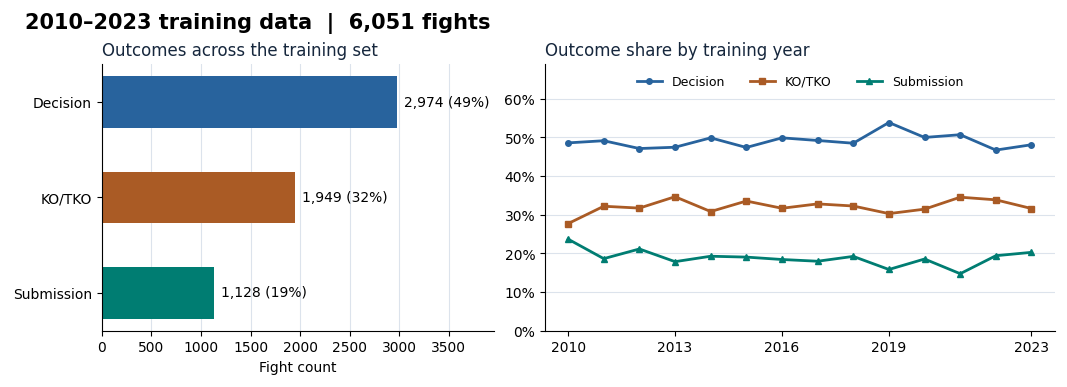

01 — Rebuild the original and modern datasets …
Finished in 104.4 seconds.
label
DEC       2688
KO/TKO    1985
SUB       1211
Building strictly prior fight histories for the full UFCStats export.
Prepared 5,884 original rows and 20 personal test bouts.
02 — Plot the training distribution …
Finished in 2.1 seconds.


In [9]:
if REFIT:
    run_python("prepare_data.py", name="01 — Rebuild the original and modern datasets")
else:
    run_python("prepare_data.py", "--preview", name="01 — Rebuild the original dataset")
show_csv(PROJECT / "prepared/splits.csv")
run_python("charts.py", "training", name="02 — Plot the training distribution", tail=0)
show_chart("training")

**Reading the training charts.** The left panel shows the class counts in the 6,051-fight modern training set. Decisions account for about half of those fights, while submissions account for about one fifth. The right panel normalizes each year separately so changes in the mix are visible even when the number of fights changes. The table above shows the chronological split for both benchmarks.

## 3. Reproduce the original multimodal experiment

The original study combines **physical and historical statistics**, **recent form**, and **fighter-profile text**. It trains on 2010–2018, tunes on 2019, and scores the resulting choices on 2020–March 2021. Fresh refits may give different scores from the published tables because this notebook uses the corrected date and stance handling and its own pinned package versions. The original profile corpus was gathered after some fights had already happened. Cleaning the text reduces obvious references to results, but these historical text experiments still have that timing limitation.

**Source · profile collection and cleaning.** The scraper supplies the same cleaning function used by the original text pipeline. Running this source cell writes the scraper. The experiment uses the committed profile snapshot. Live collection is optional later in the notebook.

In [10]:
%%writefile "{PROJECT}/scrape_profiles.py"
"""
scrape_profiles.py — build the TEXT modality for the UFC method-of-victory project.

For every fighter in the Kaggle "ufcdata" dataset (rajeevw/ufcdata), collect:
  1. Wikipedia: intro + background / early-life / fighting-style sections only
  2. UFC.com athlete page: "Fighting style", "Trains at", "Hometown" fields

Sentences that describe fight RESULTS (records, titles, wins/losses) are removed
to limit data leakage, because these pages are written today, not before each fight.

Output: fighter_profiles.csv
  fighter_name, wiki_title, wiki_text, ufc_url, ufc_text, text,
  has_wiki, has_ufc, has_profile

Usage:
  pip install requests beautifulsoup4 pandas
  python scrape_profiles.py --data data.csv --since 2010 --extra meta.csv
      (fighters from 2010 on, the training window, plus the 40 personal-set fighters)
  python scrape_profiles.py --data data.csv --since 2010 --extra meta.csv --limit 20   # quick test
  python scrape_profiles.py --debug-ufc "Israel Adesanya"   # inspect one UFC.com page

Progress is cached in profile_cache.json, so if it stops you can just rerun it.
"""

import argparse
import json
import os
import re
import time
import unicodedata

import pandas as pd
import requests
from bs4 import BeautifulSoup

HEADERS = {
    # Wikipedia asks for a descriptive User-Agent with contact info.
    "User-Agent": "UH-ML-ClassProject/1.0 (student project; contact: your-email@example.com)"
}
WIKI_API = "https://en.wikipedia.org/w/api.php"
UFC_URL = "https://www.ufc.com/athlete/{slug}"
CACHE_FILE = "profile_cache.json"
WIKI_DELAY = 0.1  # seconds between Wikipedia requests
UFC_DELAY = 0.4   # seconds between UFC.com requests; be polite

# Wikipedia sections worth keeping (matched case-insensitively against section titles)
KEEP_SECTIONS = re.compile(
    r"background|early life|fighting style|style|training|amateur|biography",
    re.I,
)
# UFC.com labels worth keeping
UFC_LABELS = ["Fighting style", "Trains at", "Hometown", "Place of Birth"]

# Sentences matching any of these get dropped (leakage filter)
LEAK_PATTERNS = re.compile(
    r"\b\d{1,2}\s*[-–]\s*\d{1,2}(\s*[-–]\s*\d{1,2})?\b"  # records like 22-1 or 10-2-1
    r"|champion|title|ranked|ranking|retire"  # not "belt": keep "BJJ black belt"
    r"|defeat|knock(ed)? out|submitted|submission win|won |win |wins |lost |loss"
    r"|record|undefeated|streak|hall of fame|fight of the night|performance of the night"
    # career-span / after-the-fact info (when a career ended, later promotions, death)
    r"|retir|former|from \d{4} (until|to) \d{4}|\([^)]*\d{4}\s*[–-][^)]*\d{4}\)|died|death|passed away|best known|stint|currently|competitor from"
    # personal-life noise that says nothing about fighting
    r"|married|wife|husband|daughter|\bson\b|children|girlfriend|arrest|accused|charged|altercation|stabb|killed"
    # life after fighting
    r"|\bis now\b|\bnow (a|an|works|runs|owns|hosts)\b|youtube|podcast|labrador|\bdogs?\b"
    # fight results and outcomes described directly
    r"|decision|\brounds?\b|\bufc \d|victor|\bbeat\b|\bt?ko\b|finish"
    # signings, releases, other promotions (usually later career)
    r"|released|signed|contract|bellator|\bpfl\b|one championship|rizin|strikeforce|\bwec\b"
    # life outside / after MMA
    r"|\bwwe\b|wrestlemania|comedy|\bactor\b|\bfilm|prison|sentenc|custody|parole|convicted"
    # anything dated 2005 or later could describe events after a training fight
    r"|\b(200[5-9]|20[1-2]\d)\b"
    # career summaries and reputation (written with hindsight)
    r"|of all time|greatest|\bbest\b|of the year|\branks?\b|most successful|controvers"
    r"|accolade|award|honou?r|regarded|considered|widely|legend|elite|top \d|#\d|\bno\. ?\d"
    r"|nicknamed|popular|famous|known as|highest|fastest|youngest|oldest|first (fighter|person|man|woman)"
    r"|suspen|\bfined?\b|commission|brawl|usada|doping|tested positive|banned",
    re.I,
)


# ----------------------------------------------------------------- helpers
def load_fighters(path, since=None):
    df = pd.read_csv(path)
    if since and "date" in df.columns:
        df = df[pd.to_datetime(df["date"], format="mixed").dt.year >= since]
    for a, b in [("R_fighter", "B_fighter"), ("r_fighter", "b_fighter")]:
        if a in df.columns and b in df.columns:
            names = pd.concat([df[a], df[b]]).dropna().astype(str).str.strip()
            return sorted(names.unique())
    for a, b in [("fighter_1", "fighter_2")]:  # personal test set meta.csv
        if a in df.columns and b in df.columns:
            return sorted(pd.concat([df[a], df[b]]).dropna().astype(str).str.strip().unique())
    if "fighter_name" in df.columns:  # raw_fighter_details.csv
        return sorted(df["fighter_name"].dropna().astype(str).str.strip().unique())
    raise ValueError("Couldn't find fighter name columns (R_fighter/B_fighter or fighter_name).")


def strip_accents(s):
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))


def norm(s):
    return re.sub(r"[^a-z ]", "", strip_accents(s).lower()).strip()


def split_sentences(text):
    return re.split(r"(?<=[.!?])\s+", text)


def remove_leaky_sentences(text):
    kept = [s for s in split_sentences(text) if s and not LEAK_PATTERNS.search(s)]
    return " ".join(kept).strip()


def load_cache():
    if os.path.exists(CACHE_FILE):
        with open(CACHE_FILE, encoding="utf-8") as f:
            return json.load(f)
    return {}


def save_cache(cache):
    with open(CACHE_FILE, "w", encoding="utf-8") as f:
        json.dump(cache, f, ensure_ascii=False, indent=1)


def get(url, **kw):
    for attempt in range(3):
        try:
            r = requests.get(url, headers=HEADERS, timeout=15, **kw)
            if r.status_code == 429:  # rate limited
                time.sleep(5 * (attempt + 1))
                continue
            return r
        except requests.RequestException:
            time.sleep(2)
    return None


# ----------------------------------------------------------------- Wikipedia
def wiki_find_title(name):
    """Search Wikipedia and return the page title for this fighter, or None."""
    r = get(WIKI_API, params={
        "action": "query", "list": "search", "format": "json", "srlimit": 5,
        "srsearch": f'"{name}" mixed martial artist',
    })
    if not r or r.status_code != 200:
        return None
    target = set(norm(name).split())
    for hit in r.json().get("query", {}).get("search", []):
        title = hit["title"]
        base = re.sub(r"\(.*?\)", "", title)  # drop "(fighter)" etc.
        snippet = hit.get("snippet", "").lower()
        if target and target <= set(norm(base).split()) and (
            "martial" in snippet or "fighter" in snippet or "ufc" in snippet
            or "(fighter)" in title.lower()
        ):
            return title
    return None


def parse_wiki_sections(plain):
    """Keep the intro + whitelisted sections from a plain-text extract with == headers ==."""
    parts = re.split(r"\n(={2,})\s*(.*?)\s*\1\n", "\n" + plain)
    # parts = [intro, '==', title1, body1, '==', title2, body2, ...]
    kept = [parts[0]]
    for i in range(1, len(parts) - 2, 3):
        title, body = parts[i + 1], parts[i + 2]
        if KEEP_SECTIONS.search(title):
            kept.append(body)
    return re.sub(r"\s+", " ", " ".join(kept)).strip()


def wiki_profile(name):
    title = wiki_find_title(name)
    time.sleep(WIKI_DELAY)
    if not title:
        return None, ""
    r = get(WIKI_API, params={
        "action": "query", "prop": "extracts", "format": "json", "redirects": 1,
        "explaintext": 1, "exsectionformat": "wiki", "titles": title,
    })
    time.sleep(WIKI_DELAY)
    if not r or r.status_code != 200:
        return title, ""
    pages = r.json().get("query", {}).get("pages", {})
    plain = next(iter(pages.values()), {}).get("extract", "") or ""
    if "may refer to" in plain.lower():
        return None, ""  # disambiguation page, not the fighter's own page
    if "martial" not in plain.lower() and "fighter" not in plain.lower():
        return None, ""  # wrong person
    return title, remove_leaky_sentences(parse_wiki_sections(plain))


# ----------------------------------------------------------------- UFC.com
def ufc_slug(name):
    s = strip_accents(name).lower()
    s = re.sub(r"['.]", "", s)
    s = re.sub(r"[^a-z0-9]+", "-", s)
    return s.strip("-")


def parse_ufc_fields(html):
    """Find label -> value pairs like 'Fighting style: Muay Thai' by label text,
    so it keeps working even if UFC.com renames its CSS classes."""
    soup = BeautifulSoup(html, "html.parser")
    fields = {}
    for label in UFC_LABELS:
        el = soup.find(string=re.compile(rf"^\s*{re.escape(label)}\s*:?\s*$", re.I))
        if not el:
            continue
        node = el.parent
        value = None
        # value is usually the next sibling element of the label element
        for sib in node.find_next_siblings():
            t = sib.get_text(" ", strip=True)
            if t:
                value = t
                break
        if not value and node.parent:  # or the next element within the parent block
            nxt = node.parent.find_next_sibling()
            if nxt:
                value = nxt.get_text(" ", strip=True)
        if value and len(value) < 120:
            fields[label] = value
    return fields


def ufc_profile(name):
    url = UFC_URL.format(slug=ufc_slug(name))
    r = get(url)
    time.sleep(UFC_DELAY)
    if not r or r.status_code != 200:
        return None, ""
    fields = parse_ufc_fields(r.text)
    if not fields:
        return url, ""
    text = ". ".join(f"{k}: {v}" for k, v in fields.items()) + "."
    return url, text


# ----------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data.csv", help="Kaggle ufcdata CSV (data.csv)")
    ap.add_argument("--out", default="fighter_profiles.csv")
    ap.add_argument("--since", type=int, default=None, help="only fighters with a fight in or after this year")
    ap.add_argument("--extra", nargs="*", default=[], help="more CSVs of fighters to include, e.g. meta.csv")
    ap.add_argument("--limit", type=int, default=None, help="only do the first N fighters (testing)")
    ap.add_argument("--debug-ufc", metavar="NAME", help="print what the UFC.com parser finds for one fighter")
    args = ap.parse_args()

    if args.debug_ufc:
        url = UFC_URL.format(slug=ufc_slug(args.debug_ufc))
        r = get(url)
        print(url, r.status_code if r else "no response")
        if r is not None:
            with open("ufc_debug.html", "w", encoding="utf-8") as f:
                f.write(r.text)
            print("Saved raw page to ufc_debug.html")
            print("Parsed fields:", parse_ufc_fields(r.text))
        return

    fighters = load_fighters(args.data, args.since)
    for extra in args.extra:
        fighters = sorted(set(fighters) | set(load_fighters(extra)))
    if args.limit:
        fighters = fighters[: args.limit]
    print(f"{len(fighters)} fighters to process")

    cache = load_cache()
    for i, name in enumerate(fighters, 1):
        if name in cache:
            continue
        wiki_title, wiki_text = wiki_profile(name)
        ufc_url, ufc_text = ufc_profile(name)
        cache[name] = {
            "wiki_title": wiki_title, "wiki_text": wiki_text,
            "ufc_url": ufc_url, "ufc_text": ufc_text,
        }
        print(f"[{i}/{len(fighters)}] {name:30s} wiki={'Y' if wiki_text else '-'} ufc={'Y' if ufc_text else '-'}")
        if i % 25 == 0:
            save_cache(cache)
    save_cache(cache)

    rows = []
    for name in fighters:
        c = cache[name]
        combined = " ".join(t for t in [c["ufc_text"], c["wiki_text"]] if t).strip()
        rows.append({
            "fighter_name": name,
            "wiki_title": c["wiki_title"], "wiki_text": c["wiki_text"],
            "ufc_url": c["ufc_url"], "ufc_text": c["ufc_text"],
            "text": combined if combined else "No profile available.",
            "has_wiki": int(bool(c["wiki_text"])),
            "has_ufc": int(bool(c["ufc_text"])),
            "has_profile": int(bool(combined)),
        })
    out = pd.DataFrame(rows)
    out.to_csv(args.out, index=False)

    # Coverage summary — put these numbers in the report / show the TA
    n = len(out)
    print("\n=== Coverage ===")
    print(f"Fighters:            {n}")
    print(f"Wikipedia text:      {out.has_wiki.sum()} ({out.has_wiki.mean():.0%})")
    print(f"UFC.com text:        {out.has_ufc.sum()} ({out.has_ufc.mean():.0%})")
    print(f"Any text:            {out.has_profile.sum()} ({out.has_profile.mean():.0%})")
    lens = out.loc[out.has_profile == 1, "text"].str.split().str.len()
    if len(lens):
        print(f"Avg words (w/ text): {lens.mean():.0f}")
    print(f"Saved -> {args.out}")


if __name__ == "__main__":
    main()

Writing <current run>/scrape_profiles.py


**Source · text features.** The text encoder marks technique keywords, applies TF-IDF to emphasize distinctive words and phrases, and compresses the sparse text representation with truncated SVD. Missing profiles carry a coverage flag. Text is used in this section and the original ensemble, while the modern statistics and two-stage experiments use fight data.

In [11]:
%%writefile "{PROJECT}/text_features.py"
"""
text_features.py — turn fighter profiles into numbers (the TEXT modality).

Per fighter, three kinds of text features:
  1. Keyword flags: martial arts background named in the profile
     (wrestling, BJJ, judo, sambo, boxing, muay thai, kickboxing, karate, taekwondo)
  2. TF-IDF + SVD: a compact summary of all the words (16 numbers)
  3. MiniLM sentence embeddings + PCA (16 numbers), if fighter_embeddings.csv exists
     (made on a machine with internet by embed_profiles.py)

The leak filter from scrape_profiles.py is re-applied on load, so the newest
filter rules hold even if the profiles were scraped with an older version.
"""
import os
import re
import sys

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from scrape_profiles import remove_leaky_sentences  # noqa: E402

KEYWORDS = {
    "wrestling": r"wrestl",
    "bjj": r"jiu.?jitsu|\bbjj\b|grappl",
    "judo": r"\bjudo",
    "sambo": r"sambo",
    "boxing": r"\bbox(?:ing|er)\b|golden gloves",
    "muay_thai": r"muay thai",
    "kickboxing": r"kickbox",
    "karate": r"karate",
    "taekwondo": r"taekwondo|tae kwon do",
    "striker": r"fighting style: (?:striker|boxer|muay thai|kickbox|karate)",
    "grappler": r"fighting style: (?:grappler|wrestler|wrestling|jiu|bjj|judo|sambo)",
}
N_SVD = 16
N_EMB = 16


def load_profiles(path="data/fighter_profiles.csv"):
    p = pd.read_csv(path)
    wiki = p["wiki_text"].fillna("")
    wiki = wiki.where(~wiki.str.contains("may refer to", case=False), "")  # disambiguation pages
    p["wiki_text"] = wiki.map(remove_leaky_sentences)
    p["ufc_text"] = p["ufc_text"].fillna("")
    p["clean_text"] = (p["ufc_text"] + " " + p["wiki_text"]).str.strip()
    p["has_profile"] = (p["clean_text"] != "").astype(float)
    p.loc[p["clean_text"] == "", "clean_text"] = "No profile available."
    return p.drop_duplicates("fighter_name").set_index("fighter_name")


def fighter_text_features(p, emb_path="data/fighter_embeddings.csv"):
    """One row of text features per fighter."""
    low = p["clean_text"].str.lower()
    F = pd.DataFrame(index=p.index)
    F["has_profile"] = p["has_profile"]
    F["text_words"] = p["clean_text"].str.split().str.len() * p["has_profile"]
    for k, pat in KEYWORDS.items():
        F[f"kw_{k}"] = low.str.contains(pat, regex=True).astype(float)

    # TF-IDF + SVD (unsupervised: never sees fight outcomes)
    tf = TfidfVectorizer(min_df=3, max_df=0.5, ngram_range=(1, 2), stop_words="english")
    M = tf.fit_transform(p["clean_text"])
    k = min(N_SVD, M.shape[1] - 1, M.shape[0] - 1)
    if k >= 1:
        Z = TruncatedSVD(n_components=k, random_state=0).fit_transform(M)
        for i in range(k):
            F[f"tfidf_{i}"] = Z[:, i]

    # MiniLM embeddings, if available
    if os.path.exists(emb_path):
        E = pd.read_csv(emb_path).drop_duplicates("fighter_name").set_index("fighter_name")
        E = E.reindex(p.index)
        ok = E.notna().all(axis=1) & (p["has_profile"] == 1)
        k = min(N_EMB, int(ok.sum()) - 1)
        if k >= 1:
            Z = PCA(n_components=k, random_state=0).fit_transform(E[ok].values)
            for i in range(k):
                F[f"emb_{i}"] = np.nan
                F.loc[ok, f"emb_{i}"] = Z[:, i]
    return F


def fight_text_features(fights, F):
    """Map per-fighter text features onto each fight (red and blue corner)."""
    out = pd.DataFrame(index=fights.index)
    for corner in ("R", "B"):
        block = F.reindex(fights[f"{corner}_fighter"].values)
        block.index = fights.index
        block = block.fillna({"has_profile": 0.0})
        block.columns = [f"{corner}_txt_{c}" for c in block.columns]
        out = out.join(block)
    # matchup: who brings which background
    for k in KEYWORDS:
        out[f"txt_any_{k}"] = out[[f"R_txt_kw_{k}", f"B_txt_kw_{k}"]].max(axis=1)
    out["txt_both_profiles"] = out["R_txt_has_profile"] * out["B_txt_has_profile"]
    return out.astype(float)


def coverage_report(fights, F):
    has = F["has_profile"].reindex(pd.concat([fights.R_fighter, fights.B_fighter]).unique()).fillna(0)
    r = F["has_profile"].reindex(fights.R_fighter).fillna(0).values
    b = F["has_profile"].reindex(fights.B_fighter).fillna(0).values
    return {
        "fighters": len(has), "fighters_with_text": int(has.sum()),
        "fights": len(fights), "fights_both_have_text": int((r * b).sum()),
    }


class TextEncoder:
    """Saveable version of fighter_text_features (keywords + TF-IDF/SVD).

    fit() learns the TF-IDF vocabulary and SVD on the training profiles;
    transform() applies the same encoding to any profiles, including fighters
    the model has never seen. Used by predict.py so new uploads are encoded
    exactly like the training data. (MiniLM embeddings are not included.)
    """

    def fit(self, p):
        self.tf = TfidfVectorizer(min_df=3, max_df=0.5, ngram_range=(1, 2), stop_words="english")
        M = self.tf.fit_transform(p["clean_text"])
        self.k = min(N_SVD, M.shape[1] - 1, M.shape[0] - 1)
        self.svd = TruncatedSVD(n_components=self.k, random_state=0).fit(M)
        return self

    def transform(self, p):
        low = p["clean_text"].str.lower()
        F = pd.DataFrame(index=p.index)
        F["has_profile"] = p["has_profile"]
        F["text_words"] = p["clean_text"].str.split().str.len() * p["has_profile"]
        for k, pat in KEYWORDS.items():
            F[f"kw_{k}"] = low.str.contains(pat, regex=True).astype(float)
        Z = self.svd.transform(self.tf.transform(p["clean_text"]))
        for i in range(self.k):
            F[f"tfidf_{i}"] = Z[:, i]
        return F


def clean_profiles(p):
    """Apply load_profiles' cleaning to an in-memory profiles table."""
    p = p.copy()
    wiki = p["wiki_text"].fillna("")
    wiki = wiki.where(~wiki.str.contains("may refer to", case=False), "")
    p["wiki_text"] = wiki.map(remove_leaky_sentences)
    p["ufc_text"] = p["ufc_text"].fillna("")
    p["clean_text"] = (p["ufc_text"] + " " + p["wiki_text"]).str.strip()
    p["has_profile"] = (p["clean_text"] != "").astype(float)
    p.loc[p["clean_text"] == "", "clean_text"] = "No profile available."
    return p.drop_duplicates("fighter_name").set_index("fighter_name")

Writing <current run>/text_features.py


**Source · model comparison.** The comparison includes linear models, tree ensembles, a neural net, and versions that combine the input modalities either before training or at the probability level. The CatBoost, LightGBM, and XGBoost ensemble averages predictions across model families and seeds.

In [12]:
%%writefile "{PROJECT}/compare_models.py"
"""
compare_models.py — try other models and model combinations.

Same data and split as train.py: train 2010–2018, validate 2019, test 2020–2021.
All choices (tuning, ensemble members, class weights) are made on 2019 only;
2020–21 is scored once at the end.

Compared:
  A. Single models on all three modalities (early fusion):
     logistic regression, random forest, extra trees, HistGradientBoosting,
     LightGBM, CatBoost, XGBoost (current), XGBoost tuned, small neural net (MLP)
  B. Late fusion: one XGBoost per modality, then
     (a) average their probabilities, (b) a stacked logistic-regression combiner
  C. Ensembles of the best single models (chosen on 2019)
  D. Class-weight tuning: nudge predicted probabilities toward the rarer classes
     (submissions), weights picked on 2019

Usage: python compare_models.py
Writes results/model_comparison.csv
"""
import itertools
import warnings

import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

from text_features import fight_text_features, fighter_text_features, load_profiles
from train import CLASSES, SEEDS, TRAIN_FROM, context_features, history_features, tabular_features, xgb

warnings.filterwarnings("ignore")


# ----------------------------------------------------------------- model zoo
def make(name, seed):
    if name == "Logistic regression":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             LogisticRegression(max_iter=4000, C=0.05, class_weight="balanced"))
    if name == "Random forest":
        return make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(
            n_estimators=500, min_samples_leaf=5, max_features="sqrt", class_weight="balanced",
            n_jobs=2, random_state=seed))
    if name == "Extra trees":
        return make_pipeline(SimpleImputer(strategy="median"), ExtraTreesClassifier(
            n_estimators=500, min_samples_leaf=5, max_features="sqrt", class_weight="balanced",
            n_jobs=2, random_state=seed))
    if name == "HistGradientBoosting":
        return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.04, max_depth=4,
                                              l2_regularization=1.0, class_weight="balanced",
                                              random_state=seed)
    if name == "LightGBM":
        return LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, subsample=0.8,
                              subsample_freq=1, colsample_bytree=0.6, min_child_samples=20,
                              class_weight="balanced", random_state=seed, verbose=-1, n_jobs=2)
    if name == "CatBoost":
        return CatBoostClassifier(iterations=600, learning_rate=0.05, depth=5, l2_leaf_reg=5,
                                  auto_class_weights="Balanced", random_seed=seed, verbose=0,
                                  thread_count=2)
    if name == "XGBoost (current)":
        m = xgb()
        m.set_params(random_state=seed)
        return m
    if name == "Neural net (MLP)":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), MLPClassifier(
            hidden_layer_sizes=(64,), alpha=0.01, early_stopping=True, max_iter=500,
            random_state=seed))
    raise ValueError(name)


NEEDS_WEIGHTS = {"XGBoost (current)", "XGBoost tuned", "Neural net (MLP)"}


def fit(model, X, y, name):
    if name in NEEDS_WEIGHTS and name != "Neural net (MLP)":
        model.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
    elif name == "Neural net (MLP)":
        # MLPClassifier has no sample weights: balance classes by oversampling
        rng = np.random.default_rng(0)
        idx = np.concatenate([rng.choice(np.where(y == c)[0], (y == 0).sum(), replace=True)
                              for c in np.unique(y)])
        model.fit(X.iloc[idx] if hasattr(X, "iloc") else X[idx], y[idx])
    else:
        model.fit(X, y)
    return model


def avg_proba(name, Xtr, ytr, Xs, maker=make):
    """Average predicted probabilities over seeds (deterministic models run once)."""
    seeds = [SEEDS[0]] if name == "Logistic regression" else SEEDS
    out = [0 for _ in Xs]
    for s in seeds:
        m = fit(maker(name, s), Xtr, ytr, name)
        for i, X in enumerate(Xs):
            out[i] = out[i] + m.predict_proba(X)
    return [p / len(seeds) for p in out]


def score(y, P):
    p = P.argmax(1)
    return round(f1_score(y, p, average="macro"), 3), round(accuracy_score(y, p), 3)


def main():
    d = pd.read_csv("data/fights.csv", parse_dates=["date"])
    y = d["label"].map({c: i for i, c in enumerate(CLASSES)}).values
    yr = d["date"].dt.year
    tr = ((yr >= TRAIN_FROM) & (yr <= 2018)).values
    va, te = (yr == 2019).values, (yr >= 2020).values

    T, H, C = tabular_features(d), history_features(d), context_features(d)
    Xt = fight_text_features(d, fighter_text_features(load_profiles()))
    X = pd.concat([T, H, Xt], axis=1)
    Xtr, Xva, Xte = X[tr], X[va], X[te]
    rows, probs = [], {}

    def record(name, group, Pva, Pte):
        probs[name] = (Pva, Pte)
        v, va_acc = score(y[va], Pva)
        t, te_acc = score(y[te], Pte)
        rows.append({"group": group, "model": name, "val_macro_f1": v,
                     "test_macro_f1": t, "test_accuracy": te_acc})
        print(f"{group:<22} {name:<42} val {v:.3f}  test {t:.3f}")

    # ---------- A. single models ----------
    singles = ["Logistic regression", "Random forest", "Extra trees", "HistGradientBoosting",
               "LightGBM", "CatBoost", "XGBoost (current)", "Neural net (MLP)"]
    for name in singles:
        Pva, Pte = avg_proba(name, Xtr, y[tr], [Xva, Xte])
        record(name, "A. single model", Pva, Pte)

    # XGBoost tuned: small grid, picked on 2019
    grid = list(itertools.product([3, 4, 6], [0.02, 0.05], [300, 600], [0.4, 0.8]))
    best, best_v = None, -1
    for depth, lr, n, col in grid:
        m = XGBClassifier(n_estimators=n, max_depth=depth, learning_rate=lr, subsample=0.8,
                          colsample_bytree=col, min_child_weight=5, reg_lambda=2.0,
                          objective="multi:softprob", eval_metric="mlogloss",
                          random_state=SEEDS[0], n_jobs=2)
        m.fit(Xtr, y[tr], sample_weight=compute_sample_weight("balanced", y[tr]))
        v = f1_score(y[va], m.predict(Xva), average="macro")
        if v > best_v:
            best, best_v = (depth, lr, n, col), v
    depth, lr, n, col = best
    print("XGBoost tuned params (depth, lr, trees, colsample):", best)

    def tuned_maker(name, s):
        return XGBClassifier(n_estimators=n, max_depth=depth, learning_rate=lr, subsample=0.8,
                             colsample_bytree=col, min_child_weight=5, reg_lambda=2.0,
                             objective="multi:softprob", eval_metric="mlogloss",
                             random_state=s, n_jobs=2)
    Pva, Pte = avg_proba("XGBoost tuned", Xtr, y[tr], [Xva, Xte], maker=tuned_maker)
    record(f"XGBoost tuned {best}", "A. single model", Pva, Pte)

    # ---------- B. late fusion ----------
    blocks = {"tabular": T, "history": pd.concat([H, C], axis=1), "text": pd.concat([Xt, C], axis=1)}
    per_va, per_te, oof = {}, {}, {}
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    idx_tr = np.where(tr)[0]
    for b, Xb in blocks.items():
        per_va[b], per_te[b] = avg_proba("XGBoost (current)", Xb[tr], y[tr], [Xb[va], Xb[te]])
        o = np.zeros((tr.sum(), 3))
        for k, (a, bb) in enumerate(skf.split(idx_tr, y[tr])):
            m = make("XGBoost (current)", k)
            m.fit(Xb[tr].iloc[a], y[tr][a], sample_weight=compute_sample_weight("balanced", y[tr][a]))
            o[bb] = m.predict_proba(Xb[tr].iloc[bb])
        oof[b] = o
    record("Late fusion: average of 3 modality models", "B. late fusion",
           sum(per_va.values()) / 3, sum(per_te.values()) / 3)
    meta = LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0)
    meta.fit(np.hstack([oof[b] for b in blocks]), y[tr])
    record("Late fusion: stacked combiner", "B. late fusion",
           meta.predict_proba(np.hstack([per_va[b] for b in blocks])),
           meta.predict_proba(np.hstack([per_te[b] for b in blocks])))

    # ---------- C. ensembles of top single models (picked on 2019) ----------
    single_rows = [r for r in rows if r["group"] == "A. single model"]
    ranked = [r["model"] for r in sorted(single_rows, key=lambda r: -r["val_macro_f1"])]
    for k in (2, 3, 4):
        members = ranked[:k]
        Pva = sum(probs[m][0] for m in members) / k
        Pte = sum(probs[m][1] for m in members) / k
        record(f"Average of top {k} on 2019: " + " + ".join(m.split(" (")[0] for m in members),
               "C. ensemble", Pva, Pte)

    # ---------- D. class-weight tuning on the best 2019 model so far ----------
    best_name = max(rows, key=lambda r: r["val_macro_f1"])["model"]
    Pva, Pte = probs[best_name]
    bw, bv = (1, 1, 1), -1
    for wk in np.arange(0.7, 1.41, 0.05):
        for ws in np.arange(0.7, 1.81, 0.05):
            w = np.array([1.0, wk, ws])
            v = f1_score(y[va], (Pva * w).argmax(1), average="macro")
            if v > bv:
                bw, bv = w, v
    record(f"{best_name} + class weights {tuple(np.round(bw, 2))}", "D. class weights",
           Pva * bw, Pte * bw)

    res = pd.DataFrame(rows)
    res.to_csv("results/model_comparison.csv", index=False)
    print("\n", res.to_string(index=False))


if __name__ == "__main__":
    main()

Writing <current run>/compare_models.py


**Source · feature families and pruning.** The validation experiment shuffles related features together and measures how much macro F1 changes. That measures how much the fitted model relies on them. It also tests removing weak groups.

In [13]:
%%writefile "{PROJECT}/feature_analysis.py"
"""
feature_analysis.py — which features helped, which didn't, and does pruning help?

1. Groups all ~320 features into readable families (physical, striking, grappling, ...).
2. Permutation importance on the 2019 validation set: shuffle one family at a time
   and measure how much macro F1 drops. Big drop = the model relies on it.
   ~0 or negative = irrelevant (or noise).
3. Pruning test: drop the families that didn't help on 2019, retrain, score on 2020–21.
   Families are chosen on validation only, so the test set stays untouched.

Usage: python feature_analysis.py
Writes results/family_importance.csv, results/feature_importance_all.csv, results/pruning.csv
"""
import re
import warnings

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_sample_weight

from text_features import fight_text_features, fighter_text_features, load_profiles
from train import CLASSES, SEEDS, TRAIN_FROM, history_features, tabular_features, xgb

warnings.filterwarnings("ignore")
N_REPEATS = 10


def family(col):
    """Map a column name to a readable feature family."""
    c = col
    if "_txt_" in c or c.startswith("txt_"):
        if "kw_" in c or "txt_any_" in c:
            return "Text: martial arts keywords"
        if "tfidf" in c or "emb_" in c:
            return "Text: TF-IDF word summary"
        return "Text: profile exists / length"
    if "_h_" in c or c.startswith("diff_h_"):
        if any(k in c for k in ("win_ko", "win_sub", "win_dec", "loss_ko", "loss_sub", "finish")):
            return "History: how recent fights ended"
        return "History: recent form & activity"
    if c.startswith("weight_class") or c in ("title_bout", "no_of_rounds"):
        return "Context: weight class, rounds, title"
    if "Stance" in c:
        return "Physical: stance"
    if re.search(r"Height|Reach|Weight_lbs|_age$|diff_age", c):
        return "Physical: height, reach, weight, age"
    if "is_debut" in c or "n_debuts" in c:
        return "Debut flags"
    if re.search(r"win_by|wins$|losses$|draw$|streak|longest|total_rounds|total_title|total_time|_title_bouts", c):
        return "Record: wins, losses, streaks, win methods"
    if "opp_" in c:
        return "Opponent stats (what opponents did to them)"
    if re.search(r"TD|SUB_ATT|REV|CTRL|GROUND|CLINCH", c):
        return "Grappling averages (takedowns, subs, control)"
    if re.search(r"STR|KD|HEAD|BODY|LEG|DISTANCE", c):
        return "Striking averages (strikes, knockdowns)"
    return "Other"


def fit_models(X, y, tr):
    models = []
    for s in SEEDS:
        m = xgb()
        m.set_params(random_state=s)
        m.fit(X[tr], y[tr], sample_weight=compute_sample_weight("balanced", y[tr]))
        models.append(m)
    return models


def ensemble_predict(models, X):
    return sum(m.predict_proba(X) for m in models).argmax(1)


def main():
    d = pd.read_csv("data/fights.csv", parse_dates=["date"])
    y = d["label"].map({c: i for i, c in enumerate(CLASSES)}).values
    yr = d["date"].dt.year
    tr = ((yr >= TRAIN_FROM) & (yr <= 2018)).values
    va, te = (yr == 2019).values, (yr >= 2020).values

    X = pd.concat([tabular_features(d), history_features(d),
                   fight_text_features(d, fighter_text_features(load_profiles()))], axis=1)
    fam = pd.Series({c: family(c) for c in X.columns})
    print(f"{X.shape[1]} features in {fam.nunique()} families")
    print(fam.value_counts().to_string(), "\n")

    models = fit_models(X, y, tr)
    Xva, yva = X[va].reset_index(drop=True), y[va]
    base = f1_score(yva, ensemble_predict(models, Xva), average="macro")
    rng = np.random.default_rng(0)

    # --- family-level permutation importance (validation set) ---
    rows = []
    for f, cols in fam.groupby(fam).groups.items():
        drops = []
        for _ in range(N_REPEATS):
            Xp = Xva.copy()
            perm = rng.permutation(len(Xp))
            Xp[list(cols)] = Xp[list(cols)].values[perm]  # shuffle the whole family together
            drops.append(base - f1_score(yva, ensemble_predict(models, Xp), average="macro"))
        rows.append({"family": f, "n_features": len(cols),
                     "f1_drop_mean": round(np.mean(drops), 4), "f1_drop_sd": round(np.std(drops), 4)})
    fi = pd.DataFrame(rows).sort_values("f1_drop_mean", ascending=False)
    fi.to_csv("results/family_importance.csv", index=False)
    print(f"Validation macro F1 (all features): {base:.3f}")
    print(fi.to_string(index=False), "\n")

    # --- per-feature gain importance (how often the trees use each feature) ---
    gain = sum(pd.Series(m.feature_importances_, index=X.columns) for m in models) / len(models)
    allf = pd.DataFrame({"feature": X.columns, "family": fam.values, "gain": gain.values})
    allf = allf.sort_values("gain", ascending=False)
    allf.to_csv("results/feature_importance_all.csv", index=False)
    unused = allf[allf.gain == 0]
    print(f"Features never used by any tree: {len(unused)}")
    print(unused.family.value_counts().to_string(), "\n")
    print("Bottom 10 used features:\n", allf[allf.gain > 0].tail(10).to_string(index=False), "\n")

    # --- pruning test: drop families that didn't help on validation ---
    weak = fi.loc[fi.f1_drop_mean <= 0, "family"].tolist()
    keep = [c for c in X.columns if fam[c] not in weak]
    res = []
    for name, cols in (("all features", list(X.columns)), ("pruned (drop unhelpful families)", keep)):
        ms = fit_models(X[cols], y, tr)
        res.append({
            "model": name, "n_features": len(cols),
            "val_macro_f1": round(f1_score(y[va], ensemble_predict(ms, X.loc[va, cols]), average="macro"), 3),
            "test_macro_f1": round(f1_score(y[te], ensemble_predict(ms, X.loc[te, cols]), average="macro"), 3),
        })
    res = pd.DataFrame(res)
    res.to_csv("results/pruning.csv", index=False)
    print("Dropped families:", weak)
    print(res.to_string(index=False))


if __name__ == "__main__":
    main()

Writing <current run>/feature_analysis.py


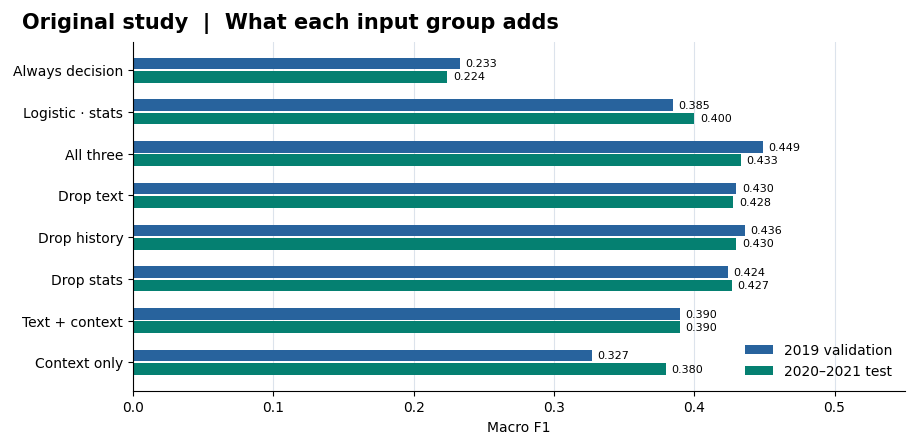

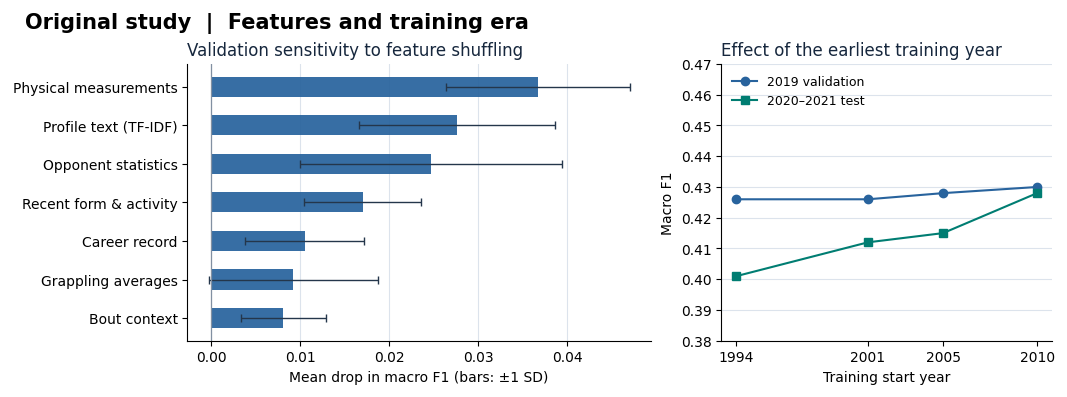

Using the published original benchmark tables.
06 — Plot the historical experiment …
Finished in 1.7 seconds.


In [14]:
if FULL:
    run_python("train.py", "--era", name="03 — Train baselines and run the input and era ablations")
    run_python("feature_analysis.py", name="04 — Measure feature importance and test pruning")
    run_python("compare_models.py", name="05 — Compare and combine the original model families")
else:
    print("Using the published original benchmark tables.")
run_python("charts.py", "historical", name="06 — Plot the historical experiment", tail=0)
show_chart("ablation")
show_chart("feature_families")

**Reading the ablation and feature charts.** “Drop text,” “Drop history,” and “Drop stats” remove one input group and fit the model again. Compare each with “All three” within the same split. In the published study, most of the single-group removals produced small changes on the test period. On the next chart, a larger drop after shuffling means the fitted model relied more on that group. The error bars show variation across validation shuffles. The right panel tests whether including older fights helps or hurts later results.

In [15]:
show_csv(PROJECT / "results/model_comparison.csv", columns=[
    "model", "val_macro_f1", "test_macro_f1", "test_accuracy",
])
show_csv(PROJECT / "results/pruning.csv")

model,val_macro_f1,test_macro_f1,test_accuracy
Logistic regression,0.406,0.407,0.422
Random forest,0.415,0.425,0.5
Extra trees,0.414,0.428,0.5
HistGradientBoosting,0.412,0.401,0.453
LightGBM,0.451,0.431,0.495
CatBoost,0.457,0.432,0.477
XGBoost (current),0.451,0.432,0.477
Neural net (MLP),0.397,0.451,0.48
"XGBoost tuned (6, 0.02, 300, 0.8)",0.443,0.441,0.495
Late fusion: average of 3 modality models,0.414,0.443,0.489


model,n_features,val_macro_f1,test_macro_f1
all features,321,0.451,0.432
pruned (drop unhelpful families),312,0.439,0.451


### Train the original ensemble and score the personal set

The final original ensemble fits five seeds per model family on all available 2010–March 2021 bouts. The personal-set analysis compares the resulting model with versions that omit one input group at a time, using the same twenty fights. These bouts illustrate individual predictions and are too few to establish season-wide accuracy.

In [16]:
%%writefile "{PROJECT}/train_final.py"
"""
train_final.py — train and save the final model used by predict_multimodal().

Final model: average of CatBoost + LightGBM + XGBoost, each averaged over 5 seeds,
trained on all three modalities for every fight from 2010 to March 2021.
Saves models/final_model.joblib with the models, the feature column list, the
fitted text encoder and the training profiles.

Usage: python train_final.py     (about 5 minutes)
"""
import os
import warnings

import joblib
import pandas as pd

from compare_models import fit, make
from text_features import TextEncoder, fight_text_features, load_profiles
from train import CLASSES, SEEDS, TRAIN_FROM, history_features, tabular_features

warnings.filterwarnings("ignore")
MEMBERS = ["CatBoost", "LightGBM", "XGBoost (current)"]


def main():
    d = pd.read_csv("data/fights.csv", parse_dates=["date"])
    d = d[d["date"].dt.year >= TRAIN_FROM].reset_index(drop=True)
    y = d["label"].map({c: i for i, c in enumerate(CLASSES)}).values

    p = load_profiles()
    enc = TextEncoder().fit(p)
    X = pd.concat([tabular_features(d), history_features(d), fight_text_features(d, enc.transform(p))], axis=1)
    print(f"Training on {len(d)} fights (2010 to March 2021), {X.shape[1]} features")

    members = {}
    for name in MEMBERS:
        members[name] = [fit(make(name, s), X, y, name) for s in SEEDS]
        print(f"  trained {name} x {len(SEEDS)} seeds")

    raw_prof = pd.read_csv("data/fighter_profiles.csv").drop_duplicates("fighter_name").set_index("fighter_name")
    os.makedirs("models", exist_ok=True)
    joblib.dump({"members": members, "columns": list(X.columns), "encoder": enc,
                 "profiles": raw_prof[["wiki_text", "ufc_text"]], "classes": CLASSES,
                 "trained_on": "UFC fights 2010 to March 2021"}, "models/final_model.joblib", compress=3)
    print("Saved models/final_model.joblib")


if __name__ == "__main__":
    main()

Writing <current run>/train_final.py


In [17]:
%%writefile "{PROJECT}/evaluate_personal.py"
"""
evaluate_personal.py — run the final model on the 2025 personal test set.

Final model: average of CatBoost + LightGBM + XGBoost (each averaged over 5 seeds),
trained on every fight from 2010 to March 2021, then scored on the 20 fights from 2025.
Also runs the modality ablation on the personal set.

Usage: python evaluate_personal.py   (after build_personal_set.py)
Writes results/personal_ablation.csv and results/personal_predictions.csv
"""
import warnings

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

from compare_models import avg_proba
from text_features import fight_text_features, fighter_text_features, load_profiles
from train import CLASSES, TRAIN_FROM, context_features, history_features, tabular_features

warnings.filterwarnings("ignore")
MEMBERS = ["CatBoost", "LightGBM", "XGBoost (current)"]


def blocks(d, F):
    T, H, C = tabular_features(d), history_features(d), context_features(d)
    X_txt = fight_text_features(d, F)
    return {"all three modalities": pd.concat([T, H, X_txt], axis=1),
            "drop text": pd.concat([T, H], axis=1),
            "drop history": pd.concat([T, X_txt], axis=1),
            "drop tabular": pd.concat([H, X_txt, C], axis=1)}


def align(Xp, cols):
    """Give the 2025 rows exactly the training columns (missing one-hot columns = 0)."""
    out = Xp.reindex(columns=cols)
    dummy = [c for c in cols if c.startswith(("weight_class_", "R_Stance_", "B_Stance_"))]
    out[dummy] = out[dummy].fillna(0)
    return out.astype(float)


def ensemble(Xtr, ytr, Xte):
    return sum(avg_proba(m, Xtr, ytr, [Xte])[0] for m in MEMBERS) / len(MEMBERS)


def main():
    d = pd.read_csv("data/fights.csv", parse_dates=["date"])
    d = d[d["date"].dt.year >= TRAIN_FROM].reset_index(drop=True)
    p = pd.read_csv("personal_test_set/fights_2025.csv", parse_dates=["date"])
    y = d["label"].map({c: i for i, c in enumerate(CLASSES)}).values
    yp = p["label"].map({c: i for i, c in enumerate(CLASSES)}).values
    F = fighter_text_features(load_profiles())
    Btr, Bp = blocks(d, F), blocks(p.drop(columns=["sample_id"]), F)
    print(f"train: {len(d)} fights (2010 to March 2021) | personal set: {len(p)} fights (2025)")

    rows, P_all = [], None
    for name in Btr:
        Xtr = Btr[name]
        P = ensemble(Xtr, y, align(Bp[name], Xtr.columns))
        pred = P.argmax(1)
        rows.append({"model": f"Ensemble: {name}", "macro_f1": round(f1_score(yp, pred, average="macro"), 3),
                     "accuracy": round(accuracy_score(yp, pred), 3), "correct": f"{(pred == yp).sum()}/{len(yp)}"})
        print(rows[-1])
        if name == "all three modalities":
            P_all = P
    maj = np.zeros(len(yp), dtype=int)  # always "DEC"
    rows.append({"model": "Majority class (always Decision)", "macro_f1": round(f1_score(yp, maj, average="macro"), 3),
                 "accuracy": round(accuracy_score(yp, maj), 3), "correct": f"{(maj == yp).sum()}/{len(yp)}"})
    pd.DataFrame(rows).to_csv("results/personal_ablation.csv", index=False)

    pred = P_all.argmax(1)
    out = p[["sample_id", "R_fighter", "B_fighter", "weight_class", "label"]].copy()
    out["predicted"] = [CLASSES[i] for i in pred]
    for i, c in enumerate(CLASSES):
        out[f"p_{c}"] = P_all[:, i].round(2)
    out["correct"] = out["predicted"] == out["label"]
    out.to_csv("results/personal_predictions.csv", index=False)
    print("\n", pd.DataFrame(rows).to_string(index=False))
    print("\nConfusion (rows = true DEC, KO/TKO, SUB):\n", confusion_matrix(yp, pred, labels=[0, 1, 2]))
    print("\n", out.to_string(index=False))


if __name__ == "__main__":
    main()

Writing <current run>/evaluate_personal.py


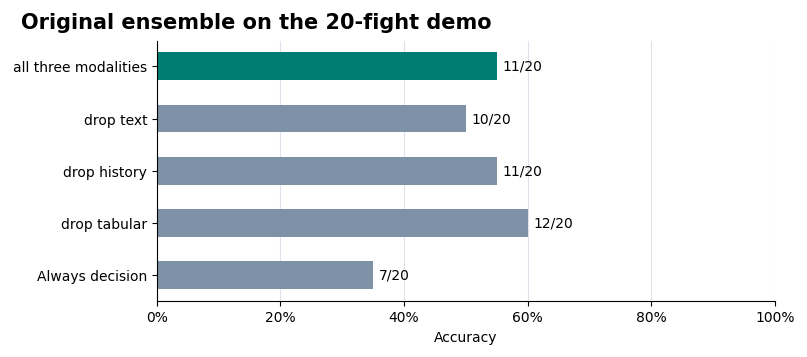

model,macro_f1,accuracy,correct
Ensemble: all three modalities,0.487,0.55,11/20
Ensemble: drop text,0.396,0.5,10/20
Ensemble: drop history,0.5,0.55,11/20
Ensemble: drop tabular,0.489,0.6,12/20
Majority class (always Decision),0.173,0.35,7/20


Using the published personal-set tables.
09 — Plot personal-set scores …
Finished in 1.4 seconds.


In [18]:
if FULL:
    run_python("train_final.py", name="07 — Fit and save the original multimodal ensemble")
    run_python("evaluate_personal.py", name="08 — Evaluate the 20-fight personal set and its ablations")
else:
    print("Using the published personal-set tables.")
run_python("charts.py", "personal", name="09 — Plot personal-set scores", tail=0)
show_chart("personal_demo")
show_csv(PROJECT / "results/personal_ablation.csv")

**Reading the personal-set chart.** Each bar shows which fraction of the twenty bouts that version got right. Labels such as 11/20 are more useful here than small percentage differences because one bout moves the accuracy by five points.

## 4. Run the full-season 2025 accuracy experiment

The modern experiment trains on 2010–2023 and chooses the model on 2024 before scoring all eligible 2025 bouts. There are five CatBoost and ensemble alternatives plus the always-decision baseline. The CatBoost comparisons change class weighting and add or omit explicit matchup features. The published accuracy winner is unweighted CatBoost, which tends to choose common outcomes.

**Source · numeric feature sets.** The stats configuration uses fighter history, physique, and bout context. The matchup variant also mixes an athlete's prior attacks with the opponent's prior defensive results. Undated text, listed weight, and stance are excluded from this modern feature set.

In [19]:
%%writefile "{PROJECT}/accuracy_features.py"
"""Pre-fight statistics used by the accuracy experiment and upload predictor."""
import pandas as pd

from train import history_features, tabular_features


def model_features(fights, feature_set, columns=None):
    # Listed weight and stance come from undated profiles. Use the bout's
    # scheduled division, and retain height, reach and age as physical data.
    tab = tabular_features(fights.drop(columns=["sample_id"], errors="ignore"))
    tab = tab.drop(columns=[c for c in tab if "Stance" in c or "Weight_lbs" in c])
    blocks = [tab, history_features(fights)]
    if feature_set == "matchups":
        matchup = {}
        for hero, opp in (("R", "B"), ("B", "R")):
            # Average of attacking accuracy and the opposing defense's concession rate.
            for stat in ("TD", "SIG_STR"):
                attack = fights[f"{hero}_avg_{stat}_landed"] / fights[f"{hero}_avg_{stat}_att"].replace(0, float("nan"))
                allowed = fights[f"{opp}_avg_opp_{stat}_landed"] / fights[f"{opp}_avg_opp_{stat}_att"].replace(0, float("nan"))
                matchup[f"{hero}_expected_{stat}_landed"] = fights[f"{hero}_avg_{stat}_att"] * (attack + allowed) / 2
            for method in ("ko", "sub"):
                matchup[f"{hero}_match_{method}"] = (fights[f"{hero}_h_win_{method}"] +
                                                     fights[f"{opp}_h_loss_{method}"]) / 2
        blocks.append(pd.DataFrame(matchup, index=fights.index))
    X = pd.concat(blocks, axis=1)
    if columns is not None:
        # Unknown event divisions have no active column in the training vocabulary.
        missing = set(columns) - set(X)
        if any(not c.startswith("weight_class_") for c in missing):
            raise ValueError(f"Missing expected numeric features: {sorted(missing)}")
        X = X.reindex(columns=columns, fill_value=0.0)
    return X.astype(float)

Writing <current run>/accuracy_features.py


**Source · accuracy-first model selection.** The loop ranks configurations by 2024 accuracy, using macro F1 to break ties. It freezes the choice before producing 2025 test predictions. The newer model is saved under `results/accuracy`.

In [20]:
%%writefile "{PROJECT}/accuracy_experiment.py"
"""Run from the repository root: python accuracy_experiment.py

Train through 2023, select on 2024 by accuracy (macro F1 breaks ties),
then evaluate the frozen choices on 2025. Output goes in results/accuracy/.
"""
import argparse
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score

from accuracy_features import model_features
from build_personal_set import build
from compare_models import fit, make
from train import CLASSES, SEEDS

ROOT = Path(__file__).resolve().parent
OUTPUT = ROOT / "results/accuracy"
FAMILIES = ("CatBoost", "LightGBM", "XGBoost (current)")


def load_rows():
    raw = pd.read_csv(ROOT / "raw_fights_greco.csv", sep=";")
    dates = pd.to_datetime(raw.date, format="mixed")
    return build(raw.loc[dates.dt.year <= 2025], pd.read_csv(ROOT / "fighter_details_greco.csv"))


def metrics(y, pred):
    return dict(n=len(y), correct=int((y == pred).sum()), accuracy=accuracy_score(y, pred),
                macro_f1=f1_score(y, pred, labels=range(3), average="macro", zero_division=0),
                submission_recall=recall_score(y, pred, labels=[2], average=None, zero_division=0)[0])


def train_one(family, seed, balanced, X, y):
    model = make(family, seed)
    if family == "CatBoost":
        model.set_params(allow_writing_files=False, auto_class_weights="Balanced" if balanced else "None")
    return fit(model, X, y, family)


def main(rows):
    OUTPUT.mkdir(parents=True, exist_ok=True)
    d = rows.loc[rows.date.dt.year.between(2010, 2025) & rows.label.isin(CLASSES)].copy()
    data = {name: d.loc[mask] for name, mask in {
        "train": d.date.dt.year < 2024, "validation": d.date.dt.year == 2024,
        "test": d.date.dt.year == 2025}.items()}
    y = {k: v.label.map(CLASSES.index).to_numpy() for k, v in data.items()}
    majority = int(np.bincount(y["train"]).argmax())
    features = {}
    for kind in ("stats", "matchups"):
        X = model_features(data["train"], kind)
        features[kind] = {"train": X, **{k: model_features(data[k], kind, X.columns)
                                         for k in ("validation", "test")}}
    # Fit each shared member once. All candidates and the tie rule are fixed in advance.
    jobs = [(family, seed, True, "stats") for family in FAMILIES for seed in SEEDS]
    jobs += [("CatBoost", 1, False, "stats"), ("CatBoost", 1, True, "matchups"),
             ("CatBoost", 1, False, "matchups")]

    def worker(job):
        family, seed, balanced, kind = job
        return train_one(family, seed, balanced, features[kind]["train"], y["train"])

    models = {}
    with ThreadPoolExecutor(max_workers=2) as pool:
        for job, model in zip(jobs, pool.map(worker, jobs)):
            models[job] = model
            print("Fit", job, flush=True)
    ensemble = "Balanced three-model ensemble (5 seeds)"
    candidates = {ensemble: jobs[:len(FAMILIES)*len(SEEDS)]}
    for kind in ("stats", "matchups"):
        for balanced in (True, False):
            name = f"CatBoost {'balanced' if balanced else 'unweighted'}, {kind}"
            candidates[name] = [("CatBoost", 1, balanced, kind)]
    baseline = "Always " + CLASSES[majority]

    def probabilities(keys, split):
        return np.mean([models[key].predict_proba(features[key[3]][split]) for key in keys], axis=0)

    def predictions(split):
        pred = {name: probabilities(keys, split).argmax(1) for name, keys in candidates.items()}
        pred[baseline] = np.full(len(y[split]), majority)
        return pred

    validation = predictions("validation")
    winner = max(validation, key=lambda name: (accuracy_score(y["validation"], validation[name]),
                                                f1_score(y["validation"], validation[name], average="macro")))
    print("Selected on 2024:", winner, flush=True)
    if winner != baseline:
        keys = candidates[winner]
        kind = keys[0][3]
        bundle = {"members": {family: [models[key] for key in keys if key[0] == family]
                              for family in sorted({key[0] for key in keys})},
                  "feature_set": kind, "columns": list(features[kind]["train"].columns),
                  "classes": CLASSES, "trained_on": "2010-2023", "selected_model": winner}
        joblib.dump(bundle, OUTPUT / "selected_model.joblib", compress=3)
    test = predictions("test")
    records = []
    for split, preds in (("validation", validation), ("test", test)):
        for name, pred in preds.items():
            records.append(dict(split=split, model=name, selected=(name == winner), **metrics(y[split], pred)))
    table = pd.DataFrame(records)
    table.to_csv(OUTPUT / "scores.csv", index=False)
    out = data["test"][["date", "R_fighter", "B_fighter", "label"]].copy()
    for name, pred in test.items():
        out[name] = np.array(CLASSES)[pred]
    if winner != baseline:
        P = probabilities(candidates[winner], "test")
        for k, label in enumerate(CLASSES):
            out[f"p_{label}"] = P[:, k]
    out.to_csv(OUTPUT / "predictions_2025.csv", index=False)
    print(table.to_string(index=False), flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--cached-rows", type=Path, help="optional trusted local feature cache")
    args = parser.parse_args()
    main(pd.read_pickle(args.cached_rows) if args.cached_rows else load_rows())

Writing <current run>/accuracy_experiment.py


In [21]:
if FULL:
    run_python("accuracy_experiment.py", "--cached-rows", "prepared/all_fights.pkl",
               name="10 — Train and evaluate the modern CatBoost and ensemble alternatives")
run_python("charts.py", "accuracy", name="11 — Prepare the accuracy comparison", tail=0)
show_csv(PROJECT / "prepared/accuracy_summary.csv")

split,model,selected,n,correct,Accuracy (%),macro_f1,Submission recall (%)
validation,Balanced three-model ensemble (5 seeds),False,511,245,47.9,0.4200615257367427,25.3
validation,"CatBoost balanced, stats",False,511,254,49.7,0.4398325664621677,27.7
validation,"CatBoost unweighted, stats",True,511,285,55.8,0.3691370648646245,0.0
validation,"CatBoost balanced, matchups",False,511,249,48.7,0.4350540162256863,30.1
validation,"CatBoost unweighted, matchups",False,511,281,55.0,0.3598560454847879,0.0
validation,Always DEC,False,511,281,55.0,0.2365319865319865,0.0
test,Balanced three-model ensemble (5 seeds),False,513,252,49.1,0.4420999367488931,26.4
test,"CatBoost balanced, stats",False,513,248,48.3,0.438290248247266,27.5
test,"CatBoost unweighted, stats",True,513,259,50.5,0.3349470123663671,1.1
test,"CatBoost balanced, matchups",False,513,252,49.1,0.4426333847356899,27.5


11 — Prepare the accuracy comparison …
Finished in 1.3 seconds.


**What to compare.** Accuracy rewards all correct picks equally, while submission recall shows how many true submissions each version recognized. In the published 2025 results, the accuracy winner was right on **259/513** bouts, only six more than always choosing decision. It caught just **one** submission.

## 5. Fit and evaluate the two-stage predictor

Different features can matter for whether a fight finishes and which finish it produces. The two-stage model splits those tasks into regularized logistic regressions.

| Learned quantity | What it uses |
|---|---|
| $f = P(mathrm{finish})$ | All training fights |
| $s = P(mathrm{submission}midmathrm{finish})$ | Only finishes from the training set |

The three displayed probabilities are $1-f$ for decision, $f(1-s)$ for KO/TKO, and $fs$ for submission. They sum to one. The features summarize both fighters' previous finishes, time since their last bout, and striking and grappling rates per minute. Sums and absolute differences keep the feature vector consistent when the red and blue corners swap.

In [22]:
%%writefile "{PROJECT}/fight_methods.py"
"""Compact, corner-invariant fight features and direct/two-stage logistic models."""
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def fight_features(d):
    blocks = []
    for corner in ("R", "B"):
        f = d.filter(regex="^" + corner + "_").copy()
        f.columns = f.columns.str[2:]
        n = f.wins + f.losses
        x = pd.DataFrame(index=d.index)
        x["bouts"] = np.log1p(n)
        x["debut"] = (n == 0).astype(float)
        for name in ("Height_cms", "Reach_cms", "age", "h_avg_rounds", "h_finish_rate",
                     "h_win_ko", "h_loss_ko", "h_win_sub", "h_loss_sub", "h_win_rate"):
            x[name] = f[name]
        for method in ("KO/TKO", "Submission"):
            x["wins_" + method] = f["win_by_" + method] / (n + 2)
        x["days_since"] = np.log1p(f.h_days_since)
        seconds = f["total_time_fought(seconds)"]
        x["mean_minutes"] = seconds / 60
        for name in ("KD","SUB_ATT","SIG_STR_landed","TD_landed","CTRL_time(seconds)"):
            for prefix in ("avg_", "avg_opp_"):
                # Small denominator floor damps rates after very short fights.
                x[prefix+name] = np.log1p(60 * f[prefix+name] / seconds.clip(lower=60))
        blocks.append(x)
    red, blue = blocks
    x = pd.concat([(red+blue).add_prefix("sum_"), (red-blue).abs().add_prefix("gap_")], axis=1)
    # If one athlete is making a debut, preserve the experienced athlete's information.
    for c in red:
        x["observed_"+c] = red[c].combine_first(blue[c]).where(red[c].isna() | blue[c].isna(), 0)
    for method in ("ko","sub"):
        a=(red["h_win_"+method]+blue["h_loss_"+method])/2
        b=(blue["h_win_"+method]+red["h_loss_"+method])/2
        x["stronger_match_"+method]=np.maximum(a,b)
    x["rounds"] = d.no_of_rounds
    x["title"] = d.title_bout.astype(int)
    return pd.concat([x,pd.get_dummies(d.weight_class, prefix="division", dtype=float)], axis=1)


class MethodModel:
    def __init__(self, two_stage):
        self.two_stage = two_stage

    def fit(self, X, y):
        self.frequency = y.value_counts(normalize=True).sort_index().to_numpy()
        def classifier():
            return make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),
                                 LogisticRegression(C=0.05,max_iter=1000))
        if self.two_stage:
            self.finish = classifier().fit(X,y.ne(0))
            self.submission = classifier().fit(X[y.ne(0)],y[y.ne(0)].eq(2))
        else:
            self.direct = classifier().fit(X,y)
        return self

    def predict_proba(self, X):
        if not self.two_stage:
            return self.direct.predict_proba(X)
        finish = self.finish.predict_proba(X)[:,1]
        sub = self.submission.predict_proba(X)[:,1]
        return np.column_stack([1-finish, finish*(1-sub), finish*sub])

Writing <current run>/fight_methods.py


**Source · select how probabilities become a pick.** The direct and two-stage models use the same training rows and features. The script checks five class adjustments on 2024 and chooses the setting with the highest macro F1 within two percentage points of each architecture's best validation accuracy. For the selected two-stage run, the pick rule divides outcome probabilities by the square root of their training frequencies. This gives rarer outcomes more weight while preserving the original probability estimates in the output. The two-stage experiment compares against the fixed, published CatBoost bundle in every run mode.

In [23]:
%%writefile "{PROJECT}/train_method_rates.py"
"""Train the direct and two-stage models; save the validation winner and test picks."""
import argparse
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

from accuracy_features import model_features
from build_personal_set import build
from fight_methods import MethodModel, fight_features
from train import CLASSES

ROOT = Path(__file__).resolve().parent
OUT = ROOT / "results/method_rates"


def load_rows():
    raw = pd.read_csv(ROOT / "raw_fights_greco.csv", sep=";")
    details = pd.read_csv(ROOT / "fighter_details_greco.csv")
    return build(raw, details)


def performance(y, pred):
    return {"n": len(y), "correct": int(np.sum(y == pred)), "accuracy": accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro"), "sub_caught": int(np.sum((y == 2) & (pred == 2))),
            "sub_actual": int(np.sum(y == 2)), "sub_picks": int(np.sum(pred == 2))}


def main(rows, output_dir=OUT, baseline_model=ROOT / "results/accuracy/selected_model.joblib"):
    output_dir.mkdir(parents=True, exist_ok=True)
    data = rows[rows.label.isin(CLASSES) & rows.date.dt.year.between(2010, 2026)]
    train = data[data.date.dt.year <= 2023]
    val = data[data.date.dt.year == 2024]
    X = fight_features(train)
    Xv = fight_features(val).reindex(columns=X.columns, fill_value=0)
    yt, yv = (d.label.map(CLASSES.index) for d in (train, val))
    models, weights, scores, validation = {}, {}, [], {}
    for name, split in (("Direct", False), ("Two-stage", True)):
        m = MethodModel(two_stage=split).fit(X, yt)
        p = m.predict_proba(Xv)
        options = []
        for alpha in (0, .25, .5, .75, 1):
            w = m.frequency ** -alpha
            options.append((w, performance(yv, (p*w).argmax(1))))
        floor = max(s["accuracy"] for _, s in options) - .02
        w, result = max((o for o in options if o[1]["accuracy"] >= floor), key=lambda o: o[1]["macro_f1"])
        models[name], weights[name], validation[name] = m, w, result
        scores.append({"year": 2024, "model": name, **result})
    winner = max(models, key=lambda name: validation[name]["macro_f1"])
    joblib.dump({"members": {winner: [models[winner]]}, "feature_set": "method_rates",
                 "columns": list(X.columns), "decision_weights": weights[winner], "classes": CLASSES,
                 "trained_on": "2010–2023", "selected_model": winner}, output_dir / "selected_model.joblib", compress=3)
    pr = joblib.load(baseline_model)
    for year in (2025, 2026):
        test = data[data.date.dt.year == year]
        Xtest = fight_features(test).reindex(columns=X.columns, fill_value=0)
        old_X = model_features(test, pr["feature_set"], pr["columns"])
        picks = {"PR CatBoost": pr["members"]["CatBoost"][0].predict_proba(old_X).argmax(1),
                 "Always decision": np.zeros(len(test), dtype=int)}
        out = test[["date", "R_fighter", "B_fighter", "label"]].copy()
        for name, model in models.items():
            prob = model.predict_proba(Xtest)
            picks[name] = (prob * weights[name]).argmax(1)
            if name == winner:
                for i, cls in enumerate(CLASSES):
                    out[f"p_{cls}"] = prob[:, i]
        y = test.label.map(CLASSES.index)
        for name, pred in picks.items():
            scores.append({"year": year, "model": name, **performance(y, pred)})
            out[name] = np.asarray(CLASSES)[pred]
        out.to_csv(output_dir / f"picks_{year}.csv", index=False)
    results = pd.DataFrame(scores)
    results.to_csv(output_dir / "scores.csv", index=False)
    print("Selected on 2024:", winner)
    print(results.to_string(index=False))


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--cached-rows", type=Path, help="optional trusted cache from build(raw, details)")
    parser.add_argument("--baseline-model", type=Path,
                        default=ROOT / "results/accuracy/selected_model.joblib")
    args = parser.parse_args()
    main(pd.read_pickle(args.cached_rows) if args.cached_rows else load_rows(), baseline_model=args.baseline_model)

Writing <current run>/train_method_rates.py


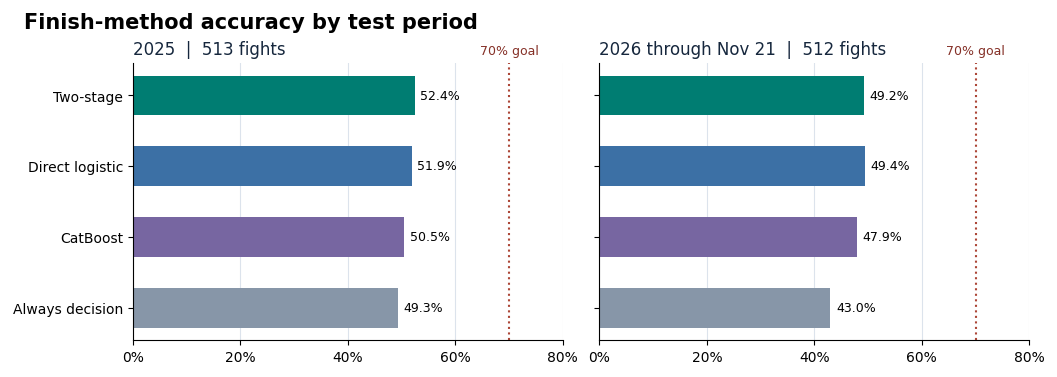

12 — Fit, select, and evaluate the two-stage and direct models …
Finished in 1.6 seconds.
Selected on 2024: Two-stage
 year           model   n  correct  accuracy  macro_f1  sub_caught  sub_actual  sub_picks
 2024          Direct 511      272  0.532290  0.438660          15          83         57
 2024       Two-stage 511      277  0.542074  0.445714          14          83         56
 2025     PR CatBoost 513      259  0.504873  0.334947           1          91          8
 2025 Always decision 513      253  0.493177  0.220191           0          91          0
 2025          Direct 513      266  0.518519  0.434077          15          91         57
 2025       Two-stage 513      269  0.524366  0.440474          16          91         55
 2026     PR CatBoost 512      245  0.478516  0.342404           2          87          3
 2026 Always decision 512      220  0.429688  0.200364           0          87          0
 2026          Direct 512      253  0.494141  0.422211          13      

In [24]:
if REFIT:
    run_python("train_method_rates.py", "--cached-rows", "prepared/all_fights.pkl",
               "--baseline-model", PUBLISHED / BASELINE_ASSET,
               name="12 — Fit, select, and evaluate the two-stage and direct models", tail=15)
run_python("charts.py", "later", name="13 — Plot modern accuracy and classification errors")
show_chart("later_accuracy")

**Reading the test-accuracy chart.** Each bar is the share of all bouts its method got right. Both logistic models are close in accuracy. In the published results the two-stage model scored **52.4%** in 2025 and **49.2%** in the available 2026 fights, below the dotted **70%** goal. The 2025 sample includes the twenty previously examined examples. The 2026 sample extends through November 21.

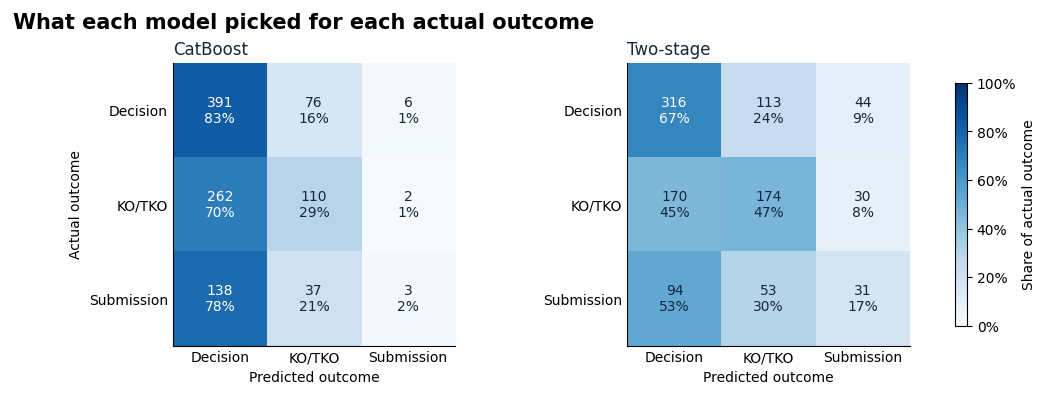

Period,Model,Fights,Correct,Accuracy,Submissions caught,Submission picks
2025,Two-stage,513,269,52.4%,16/91,55
2025,Direct logistic,513,266,51.9%,15/91,57
2025,CatBoost,513,259,50.5%,1/91,8
2025,Always decision,513,253,49.3%,0/91,0
2026,Two-stage,512,252,49.2%,15/87,50
2026,Direct logistic,512,253,49.4%,13/87,48
2026,CatBoost,512,245,47.9%,2/87,3
2026,Always decision,512,220,43.0%,0/87,0
Both periods,Two-stage,1025,521,50.8%,31/178,105
Both periods,Direct logistic,1025,519,50.6%,28/178,105


In [25]:
show_chart("later_confusion")
show_csv(PROJECT / "prepared/later_scores.csv", limit=12)

**Reading the confusion matrices.** Read across a row to see what the model picked for that actual outcome. The diagonal contains correct calls. Cell percentages are measured within each actual outcome, so submission performance is visible despite the smaller class. The published two-stage run caught **31 of 178** submissions compared with **3** for CatBoost. It predicted submission 105 times, including 74 misses.

Across 1,025 fights, the previously reported two-stage accuracy gain was **1.7 percentage points**. The paired interval resamples whole event dates, keeping outcomes on the same card together. Its published range of **−1.6 to +5.0 points** includes zero, so the increase could be due to chance.

## 6. Make predictions from the notebook

The predictor uses each target fight's date to select completed bouts strictly before it. For the target itself it builds a placeholder carrying only known matchup context. It aligns those features to the saved model's schema and returns the predicted category and three probabilities. If a bundle has class adjustments, the decision rule applies them to choose the category.

The upload interface accepts a folder containing `fights.csv`, `raw_fights.csv`, and `fighter_details.csv`. An optional `fighter_profiles.csv` supplies text for the original ensemble, and an optional `labels.csv` scores known outcomes. The default below runs the repository's 20-fight example.

In [26]:
%%writefile "{PROJECT}/predict.py"
"""
predict.py — the project's entry point: predict_multimodal().

    from predict import predict_multimodal
    preds = predict_multimodal("personal_test_set/upload")

Give it a folder ("upload") with:
  fights.csv           the fights to predict: sample_id, date, R_fighter, B_fighter,
                       weight_class, title_bout, no_of_rounds
  raw_fights.csv       UFC fight history for these fighters, Kaggle raw format (';'-separated)
  fighter_details.csv  fighter_name, Height, Weight, Reach, Stance, DOB
  fighter_profiles.csv (optional) text profiles; fighters without one get "No profile available"

It returns one row per fight with the predicted method (KO/TKO, SUB, DEC) and the
probability of each.

How it works, for each fight:
  1. TABULAR  : pre-fight stats from the fighters' earlier fights (same math as Kaggle data.csv)
  2. HISTORY  : each fighter's last 5 fights (results, methods, rounds, layoff)
  3. TEXT     : martial-arts keywords + TF-IDF summary of each fighter's profile
  4. One row per fight -> CatBoost, LightGBM and XGBoost (5 seeds each) -> average probabilities

Only fights BEFORE each fight's date are used. If the fight itself is in raw_fights.csv,
it is replaced by a blank placeholder, so its result can never leak into the prediction.

The trained model lives in models/final_model.joblib (made by train_final.py).
"""
import os
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from build_personal_set import build
from text_features import clean_profiles, fight_text_features
from train import CLASSES, history_features, tabular_features

ROOT = Path(__file__).resolve().parent
MODEL_PATH = ROOT / "models/final_model.joblib"
if not MODEL_PATH.exists():
    MODEL_PATH = ROOT / "final_model.joblib"
WC_NAMES = {"WomenStrawweight": "Women's Strawweight", "WomenFlyweight": "Women's Flyweight",
            "WomenBantamweight": "Women's Bantamweight", "WomenFeatherweight": "Women's Featherweight",
            "LightHeavyweight": "Light Heavyweight", "CatchWeight": "Catch Weight", "OpenWeight": "Open Weight"}
STAT_COLS = ["KD", "SIG_STR.", "SIG_STR_pct", "TOTAL_STR.", "TD", "TD_pct", "SUB_ATT", "REV", "CTRL",
             "HEAD", "BODY", "LEG", "DISTANCE", "CLINCH", "GROUND"]
BLANK = {"KD": 0, "SIG_STR_pct": "---", "TD_pct": "---", "SUB_ATT": 0, "REV": 0, "CTRL": "0:00"}


def _placeholder(f):
    """A blank row for the fight being predicted: right date, corners, weight class, rounds.
    Its stats are empty and it has no result, so nothing about the outcome is used."""
    wc = WC_NAMES.get(f.weight_class, f.weight_class)
    fight_type = f"UFC {wc} Title Bout" if bool(f.title_bout) else f"{wc} Bout"
    rounds = int(f.no_of_rounds)
    row = {"R_fighter": f.R_fighter, "B_fighter": f.B_fighter, "win_by": "", "last_round": 1,
           "last_round_time": "0:00", "Referee": "", "date": f.date, "location": "",
           "Format": f"{rounds} Rnd ({'-'.join(['5'] * rounds)})", "Fight_type": fight_type, "Winner": np.nan}
    for c in STAT_COLS:
        row["R_" + c] = row["B_" + c] = BLANK.get(c, "0 of 0")
    return row


def build_features(fights, raw, details, profiles, bundle):
    """Model-ready feature matrix for the fights, with exactly the training columns."""
    fights = fights.copy()
    fights["date"] = pd.to_datetime(fights["date"], format="mixed")
    raw = raw.copy()
    raw["_d"] = pd.to_datetime(raw["date"], format="mixed")
    # Each date sees only completed history from earlier dates. A target in a
    # previous event keeps its real result if it is present in the supplied history.
    parts = []
    for date, group in fights.groupby("date", sort=False):
        names = set(group.R_fighter) | set(group.B_fighter)
        past = raw.loc[(raw._d < date) &
                       (raw.R_fighter.isin(names) | raw.B_fighter.isin(names))].drop(columns="_d")
        placeholders = pd.DataFrame([_placeholder(row) for _, row in group.iterrows()])
        history = pd.concat([past, placeholders], ignore_index=True) if len(past) else placeholders
        targets = group[["sample_id", "R_fighter", "B_fighter", "date"]]
        parts.append(build(history, details, targets))
    d = pd.concat(parts).set_index("sample_id").loc[fights["sample_id"]].reset_index()

    if bundle.get("feature_set") == "method_rates":
        from fight_methods import fight_features
        return d, fight_features(d).reindex(columns=bundle["columns"], fill_value=0)

    if bundle.get("feature_set") in ("stats", "matchups"):
        from accuracy_features import model_features
        X = model_features(d, bundle["feature_set"], bundle["columns"])
        return d, X

    return d, legacy_features(d, profiles, bundle)


def legacy_features(d, profiles, bundle):
    # Training profiles are overridden by any uploaded profiles.
    p = bundle["profiles"]
    if profiles is not None:
        p = pd.concat([p[~p.index.isin(profiles["fighter_name"])].reset_index(),
                       profiles]).reset_index(drop=True)
        p = clean_profiles(p)
    else:
        p = clean_profiles(p.reset_index())
    names = set(d.R_fighter) | set(d.B_fighter)
    missing = sorted(names - set(p.index))
    if missing:
        extra = pd.DataFrame({"fighter_name": missing, "wiki_text": "", "ufc_text": ""})
        p = clean_profiles(pd.concat([p.reset_index()[["fighter_name", "wiki_text", "ufc_text"]], extra]))
    F = bundle["encoder"].transform(p)

    X = pd.concat([tabular_features(d.drop(columns=["sample_id"], errors="ignore")), history_features(d),
                   fight_text_features(d, F)], axis=1)
    X = X.loc[:, ~X.columns.duplicated()].reindex(columns=bundle["columns"])
    dummies = [c for c in bundle["columns"] if c.startswith(("weight_class_", "R_Stance_", "B_Stance_"))]
    X[dummies] = X[dummies].fillna(0)
    return X.astype(float)


def predict_multimodal(upload_dir, model_path=MODEL_PATH):
    """Predict how each fight in upload_dir/fights.csv ends. Returns a DataFrame."""
    bundle = joblib.load(model_path)
    fights = pd.read_csv(os.path.join(upload_dir, "fights.csv"))
    raw = pd.read_csv(os.path.join(upload_dir, "raw_fights.csv"), sep=";")
    details = pd.read_csv(os.path.join(upload_dir, "fighter_details.csv"))
    prof_path = os.path.join(upload_dir, "fighter_profiles.csv")
    profiles = pd.read_csv(prof_path) if os.path.exists(prof_path) else None

    d, X = build_features(fights, raw, details, profiles, bundle)
    P = 0
    for name, models in bundle["members"].items():
        P = P + sum(m.predict_proba(X) for m in models) / len(models)
    P = P / len(bundle["members"])

    out = fights[["sample_id", "R_fighter", "B_fighter"]].copy()
    # Use the validation-selected class weights for picks. Keep the raw probabilities.
    picks = (P * np.asarray(bundle.get("decision_weights", 1.0))).argmax(1)
    out["predicted"] = [CLASSES[i] for i in picks]
    for i, c in enumerate(CLASSES):
        out[f"p_{c}"] = P[:, i].round(3)
    return out

Writing <current run>/predict.py


In [27]:
%%writefile "{PROJECT}/run.py"
"""
run.py — upload/run harness: predict a folder of fights and, if answers are given, score them.

Usage:
  python run.py --input personal_test_set/upload
  python run.py --input my_fights/ --out my_predictions.csv

The input folder needs fights.csv, raw_fights.csv, fighter_details.csv and optionally
fighter_profiles.csv (see predict.py). If it also has labels.csv (sample_id, label),
the script prints macro F1, accuracy and a fight-by-fight table.
"""
import argparse
import os
import warnings

import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

from predict import MODEL_PATH, predict_multimodal
from train import CLASSES

warnings.filterwarnings("ignore")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input", required=True, help="upload folder")
    ap.add_argument("--out", default=None, help="where to save predictions (default: <input>/predictions.csv)")
    ap.add_argument("--model", default=MODEL_PATH, help="trained model bundle")
    args = ap.parse_args()

    preds = predict_multimodal(args.input, model_path=args.model)
    out = args.out or os.path.join(args.input, "predictions.csv")

    lab_path = os.path.join(args.input, "labels.csv")
    if os.path.exists(lab_path):
        lab = pd.read_csv(lab_path)[["sample_id", "label"]]
        preds = preds.merge(lab, on="sample_id", how="left")
        preds["correct"] = preds["predicted"] == preds["label"]
        y, p = preds["label"], preds["predicted"]
        print(f"Macro F1: {f1_score(y, p, average='macro'):.3f}   "
              f"Accuracy: {accuracy_score(y, p):.3f} ({preds['correct'].sum()}/{len(preds)})")
        print("Confusion matrix (rows = true, columns = predicted):")
        print(pd.DataFrame(confusion_matrix(y, p, labels=CLASSES), index=CLASSES, columns=CLASSES), "\n")

    print(preds.to_string(index=False))
    preds.to_csv(out, index=False)
    print(f"\nSaved {out}")


if __name__ == "__main__":
    main()

Writing <current run>/run.py


In [28]:
%%writefile "{PROJECT}/demo_check.py"
"""Compare the exported predictions with the two-stage test records."""
import numpy as np
import pandas as pd


keys = ["date", "R_fighter", "B_fighter"]
card = pd.read_csv("fights.csv")
demo = pd.read_csv("results/notebook_demo_two_stage.csv").merge(
    card[["sample_id", "date"]], on="sample_id", validate="one_to_one",
)
reference = pd.read_csv("results/method_rates/picks_2025.csv")
match = demo.merge(reference, on=keys, validate="one_to_one", suffixes=("_demo", "_test"))
assert len(match) == len(card) == 20
assert match.predicted.eq(match["Two-stage"]).all()
for p in ["p_DEC", "p_KO/TKO", "p_SUB"]:
    np.testing.assert_allclose(match[p + "_demo"], match[p + "_test"].round(3), rtol=0, atol=1e-10)
print(f"Verified {len(match)} picks and {3 * len(match)} model probabilities.")

Writing <current run>/demo_check.py


In [29]:
two_stage_bundle = PROJECT / "results/method_rates/selected_model.joblib"
two_stage_predictions = PROJECT / "results/notebook_demo_two_stage.csv"
run_python("run.py", "--input", PROJECT, "--model", two_stage_bundle, "--out", two_stage_predictions,
           name="14 — Score the 20-fight example with the two-stage model", tail=3)
run_python("demo_check.py", name="15 — Check demo picks against the full-season evaluation")
show_csv(two_stage_predictions, columns=[
    "sample_id", "R_fighter", "B_fighter", "predicted", "label", "p_DEC", "p_KO/TKO", "p_SUB",
], limit=8)
if FULL:
    legacy_predictions = PROJECT / "results/notebook_demo_ensemble.csv"
    run_python("run.py", "--input", PROJECT, "--model", PROJECT / "models/final_model.joblib",
               "--out", legacy_predictions, name="16 — Score the example with the refitted ensemble", tail=3)

sample_id,R_fighter,B_fighter,predicted,label,p_DEC,p_KO/TKO,p_SUB
P01,Alexandre Pantoja,Kai Kara-France,DEC,SUB,0.522,0.291,0.186
P02,Beneil Dariush,Renato Moicano,SUB,DEC,0.394,0.308,0.298
P03,Jack Hermansson,Gregory Rodrigues,DEC,KO/TKO,0.505,0.38,0.115
P04,Ilia Topuria,Charles Oliveira,SUB,KO/TKO,0.267,0.381,0.352
P05,Niko Price,Jacobe Smith,KO/TKO,SUB,0.352,0.488,0.16
P06,Hyder Amil,Jose Delgado,KO/TKO,KO/TKO,0.403,0.502,0.095
P07,Brandon Royval,Joshua Van,DEC,DEC,0.517,0.29,0.194
P08,Payton Talbott,Felipe Lima,DEC,DEC,0.479,0.254,0.267


14 — Score the 20-fight example with the two-stage model …
Finished in 5.5 seconds.
      P20       Josh Emmett        Youssef Zalal       DEC  0.736     0.186  0.078    SUB    False

Saved <current run>/results/notebook_demo_two_stage.csv
15 — Check demo picks against the full-season evaluation …
Finished in 0.4 seconds.
Verified 20 picks and 60 model probabilities.
Showing 8 of 20 rows. See notebook_demo_two_stage.csv for the full table.


### Predict your own card

Set `CUSTOM_UPLOAD_DIR` to the Colab folder that holds your input files and rerun the next cell. Use `sample_id, date, R_fighter, B_fighter, weight_class, title_bout, no_of_rounds` as the columns of `fights.csv`. Match fighter names to the raw history and details. The bundled `fights.csv` is a working template.

In [30]:
CUSTOM_UPLOAD_DIR = ""  # @param {type:"string"}
DOWNLOAD_PREDICTIONS = False  # @param {type:"boolean"}

predictions_to_download = two_stage_predictions
if CUSTOM_UPLOAD_DIR:
    upload = Path(CUSTOM_UPLOAD_DIR).expanduser().resolve()
    missing = [name for name in ("fights.csv", "raw_fights.csv", "fighter_details.csv")
               if not (upload / name).is_file()]
    if missing:
        raise FileNotFoundError(f"Missing in {upload}: {', '.join(missing)}")
    predictions_to_download = PROJECT / "results/notebook_custom_predictions.csv"
    run_python("run.py", "--input", upload, "--model", two_stage_bundle,
               "--out", predictions_to_download, name="Predict the uploaded card", tail=3)
    show_csv(predictions_to_download, limit=10)
if DOWNLOAD_PREDICTIONS:
    from google.colab import files
    files.download(str(predictions_to_download))
else:
    print(f"CSV available at {predictions_to_download}")

CSV available at <current run>/results/notebook_demo_two_stage.csv


### Check the feature pipeline

These tests use small, deliberately constructed cards. They check that same-day outcomes stay out of history, completed earlier bouts are available to later dates, and categorical features remain stable when a fight is scored alone.

In [31]:
%%writefile "{PROJECT}/test_accuracy_features.py"
import unittest
from pathlib import Path

import pandas as pd
from pandas.testing import assert_frame_equal

from build_personal_set import build
from predict import build_features
from train import tabular_features


class FeatureTests(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        root = Path(__file__).parent
        source = pd.read_csv(root / "raw_fights.csv", sep=";").iloc[0]
        details = pd.read_csv(root / "fighter_details.csv").iloc[0]
        def make(date, red, blue):
            row = source.copy()
            row.update(pd.Series(dict(date=date, R_fighter=red, B_fighter=blue, Winner=red,
                                      win_by="Submission", Fight_type="Lightweight Bout")))
            return row
        cls.raw = pd.DataFrame([make("2022-01-01", "A", "B"), make("2022-01-01", "A", "C"),
                                make("2022-02-01", "A", "D")]).reset_index(drop=True)
        cls.details = pd.DataFrame([dict(details, fighter_name=name, Stance=stance)
                                    for name, stance in zip("ABCD", ["Orthodox", "Southpaw"] * 2)])
        cls.fights = cls.raw.iloc[[0, 2]][["date", "R_fighter", "B_fighter"]].assign(
            sample_id=["first", "later"], weight_class="Lightweight", title_bout=0, no_of_rounds=3)

    def test_strict_cutoff_in_both_feature_families(self):
        d = build(self.raw, self.details)
        first_day = d[d.date == pd.Timestamp("2022-01-01")]
        self.assertEqual(first_day.R_h_n_prev.tolist(), [0, 0])
        self.assertEqual(first_day.R_wins.tolist(), [0, 0])
        self.assertEqual(d.loc[d.date == pd.Timestamp("2022-02-01"), "R_wins"].item(), 2)

    def test_known_results_preserved_across_batch_dates(self):
        bundle = {"feature_set": "stats", "columns": ["R_wins", "R_h_win_sub"]}
        _, batch = build_features(self.fights, self.raw, self.details, None, bundle)
        _, one = build_features(self.fights.tail(1), self.raw, self.details, None, bundle)
        assert_frame_equal(batch.tail(1).reset_index(drop=True), one)
        self.assertEqual(one.R_wins.item(), 2)

    def test_stance_columns_independent_of_batch(self):
        d = build(self.raw, self.details)
        d.loc[d.index[-1], ["R_Stance", "B_Stance"]] = ["Southpaw", "Orthodox"]
        one = tabular_features(d.iloc[:1]).filter(like="diff_Stance")
        full = tabular_features(d).iloc[:1].filter(like="diff_Stance")
        assert_frame_equal(one, full)
        self.assertEqual(one["diff_Stance_Orthodox"].item(), 1)


if __name__ == "__main__":
    unittest.main()

Writing <current run>/test_accuracy_features.py


In [32]:
run_python("-m", "unittest", "test_accuracy_features", name="17 — Verify the pre-fight feature checks")

17 — Verify the pre-fight feature checks …
Finished in 1.6 seconds.
...
----------------------------------------------------------------------
Ran 3 tests in 0.355s

OK


## 7. Optional data collection and original-model replay

The normal experiments use the frozen snapshots so reruns use the same fight records. These tools are included for refreshing or inspecting the sources. Fresh downloads and scraping can differ from the snapshots, and live pages can refuse automated requests.

**Source · convert the published UFCStats export.** The converter sums per-round records into a bout and writes the same raw format used by the feature builder.

In [33]:
%%writefile "{PROJECT}/convert_greco.py"
"""
convert_greco.py — convert published UFCStats data into the Kaggle raw format.

UFCStats now blocks plain scripts with a browser check, so instead of scraping we use
the public, regularly updated UFCStats export at github.com/Greco1899/scrape_ufc_stats:
  ufc_event_details.csv, ufc_fight_results.csv, ufc_fight_stats.csv (per round),
  ufc_fighter_tott.csv (height, weight, reach, stance, DOB)

This script turns them into the same columns as raw_total_fight_data.csv and
raw_fighter_details.csv, so ufc_features.py can compute pre-fight stats exactly like
the training data. Per-round stats are summed into fight totals.

Usage:
  python convert_greco.py --src <folder with the 4 CSVs>
  (or with no --src: downloads them from GitHub)

Outputs (personal_test_set/):
  raw_fights_greco.csv     every UFC fight, newest first (semicolon-separated)
  fighter_details_greco.csv
"""
import argparse
import os

import numpy as np
import pandas as pd

REPO = "https://raw.githubusercontent.com/Greco1899/scrape_ufc_stats/main/"
FILES = ["ufc_event_details.csv", "ufc_fight_results.csv", "ufc_fight_stats.csv", "ufc_fighter_tott.csv"]
OF_COLS = {"SIG.STR.": "SIG_STR.", "TOTAL STR.": "TOTAL_STR.", "TD": "TD", "HEAD": "HEAD", "BODY": "BODY",
           "LEG": "LEG", "DISTANCE": "DISTANCE", "CLINCH": "CLINCH", "GROUND": "GROUND"}
OUT = "personal_test_set/"


def load(src):
    if src:
        return [pd.read_csv(os.path.join(src, f)) for f in FILES]
    return [pd.read_csv(REPO + f) for f in FILES]


def _of(series):
    parts = series.fillna("0 of 0").astype(str).str.split(" of ")
    return parts.str[0].astype(float).fillna(0), parts.str[1].astype(float).fillna(0)


def _sec(series):
    def f(x):
        if pd.isna(x) or x in ("--", ""):
            return 0
        m, s = str(x).split(":")
        return int(m) * 60 + int(s)
    return series.map(f)


def totals(stats):
    """Sum per-round rows into one row per (bout URL-free key, fighter)."""
    s = stats.copy()
    s["EVENT"], s["BOUT"], s["FIGHTER"] = s["EVENT"].str.strip(), s["BOUT"].str.strip(), s["FIGHTER"].str.strip()
    agg = {}
    for c, k in OF_COLS.items():
        s[k + "_l"], s[k + "_a"] = _of(s[c])
        agg[k + "_l"] = "sum"; agg[k + "_a"] = "sum"
    for c, k in (("KD", "KD"), ("SUB.ATT", "SUB_ATT"), ("REV.", "REV")):
        s[k] = pd.to_numeric(s[c], errors="coerce").fillna(0)
        agg[k] = "sum"
    s["CTRL_s"] = _sec(s["CTRL"])
    agg["CTRL_s"] = "sum"
    t = s.groupby(["EVENT", "BOUT", "FIGHTER"], sort=False).agg(agg).reset_index()
    for k in OF_COLS.values():
        t[k] = t[k + "_l"].astype(int).astype(str) + " of " + t[k + "_a"].astype(int).astype(str)
    # UFCStats percentages are whole numbers, rounded down; "---" when nothing was attempted
    pct = lambda l, a: np.where(a > 0, (np.floor(100 * l / a.replace(0, 1))).astype(int).astype(str) + "%", "---")
    t["SIG_STR_pct"] = pct(t["SIG_STR._l"], t["SIG_STR._a"])
    t["TD_pct"] = pct(t["TD_l"], t["TD_a"])
    t["CTRL"] = (t["CTRL_s"] // 60).astype(int).astype(str) + ":" + (t["CTRL_s"] % 60).astype(int).astype(str).str.zfill(2)
    for k in ("KD", "SUB_ATT", "REV"):
        t[k] = t[k].astype(int)
    return t.set_index(["EVENT", "BOUT", "FIGHTER"])


def convert(events, results, stats, tott):
    ev = events.assign(EVENT=events["EVENT"].str.strip()).drop_duplicates("EVENT").set_index("EVENT")
    t = totals(stats)
    rows = []
    for _, r in results.iterrows():
        event, bout = str(r["EVENT"]).strip(), str(r["BOUT"]).strip()
        names = [n.strip() for n in bout.split(" vs. ")]
        if len(names) != 2 or event not in ev.index:
            continue
        a, b = names
        if (event, bout, a) not in t.index or (event, bout, b) not in t.index:
            continue  # no stats for this fight
        ta, tb = t.loc[(event, bout, a)], t.loc[(event, bout, b)]
        outcome = str(r["OUTCOME"]).strip()
        winner = a if outcome == "W/L" else b if outcome == "L/W" else np.nan
        row = {"R_fighter": a, "B_fighter": b}
        for k in ["KD", "SIG_STR.", "SIG_STR_pct", "TOTAL_STR.", "TD", "TD_pct", "SUB_ATT", "REV", "CTRL",
                  "HEAD", "BODY", "LEG", "DISTANCE", "CLINCH", "GROUND"]:
            row["R_" + k], row["B_" + k] = ta[k], tb[k]
        row.update({
            "win_by": str(r["METHOD"]).strip(), "last_round": int(r["ROUND"]),
            "last_round_time": str(r["TIME"]).strip(), "Format": str(r["TIME FORMAT"]).strip(),
            "Referee": r["REFEREE"], "date": ev.at[event, "DATE"], "location": ev.at[event, "LOCATION"],
            "Fight_type": str(r["WEIGHTCLASS"]).strip(), "Winner": winner,
        })
        rows.append(row)
    raw = pd.DataFrame(rows)
    raw["_d"] = pd.to_datetime(raw["date"], format="mixed")
    raw = raw.sort_values("_d", ascending=False, kind="stable").drop(columns="_d").reset_index(drop=True)

    det = tott.rename(columns={"FIGHTER": "fighter_name", "HEIGHT": "Height", "WEIGHT": "Weight",
                               "REACH": "Reach", "STANCE": "Stance", "DOB": "DOB"})
    det = det[["fighter_name", "Height", "Weight", "Reach", "Stance", "DOB"]].replace("--", np.nan)
    det["fighter_name"] = det["fighter_name"].str.strip()
    return raw, det.drop_duplicates("fighter_name")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--src", help="folder with the 4 Greco1899 CSVs (default: download)")
    args = ap.parse_args()
    raw, det = convert(*load(args.src))
    raw.to_csv(OUT + "raw_fights_greco.csv", sep=";", index=False)
    det.to_csv(OUT + "fighter_details_greco.csv", index=False)
    print(f"Saved {len(raw)} fights and {len(det)} fighters to {OUT}")


if __name__ == "__main__":
    main()

Writing <current run>/convert_greco.py


**Source · original UFCStats scraper.** This historical collector looks up the two personal-test events and gathers the fight records. For a reproducible run, the notebook uses the committed export.

In [34]:
%%writefile "{PROJECT}/scrape_ufcstats.py"
"""
scrape_ufcstats.py — collect raw UFCStats data for the personal test set.

For each of the 20 personal-set fights (UFC 317 and UFC 320, 2025) this script:
  1. finds the fight on the event page,
  2. opens both fighters' pages (height, reach, weight, stance, date of birth),
  3. scrapes EVERY UFC fight on each fighter's record, in the same raw format as the
     Kaggle file raw_total_fight_data.csv (so ufc_features.py can compute pre-fight
     stats exactly like the training data).

Page parsing follows the original dataset's scraper
(github.com/WarrierRajeev/UFC-Predictions, src/createdata/scrape_*.py).

Outputs (in personal_test_set/):
  raw_fights_2025.csv      every fight on the 40 fighters' records (semicolon-separated)
  fighter_details_2025.csv height, weight, reach, stance, DOB for the 40 fighters
  target_fights.csv        sample_id -> red/blue corner, fight URL, event, date

Usage:
  pip install requests beautifulsoup4 pandas
  python scrape_ufcstats.py
  python scrape_ufcstats.py --debug      # save the first fight page as ufcstats_debug.html
  python scrape_ufcstats.py --events <UFC 317 event link> <UFC 320 event link>

Progress is cached in ufcstats_cache.json, so rerunning continues where it stopped.
"""
import argparse
import json
import os
import re
import time
import unicodedata

import pandas as pd
import requests
from bs4 import BeautifulSoup

BASE = "http://ufcstats.com"
EVENTS_URL = BASE + "/statistics/events/completed?page=all"
EVENTS = {"UFC 317": "2025-06-28", "UFC 320": "2025-10-04"}
META = "personal_test_set/meta.csv"
OUT = "personal_test_set/"
CACHE = "ufcstats_cache.json"
DELAY = 0.4
HEADER = ["R_fighter", "B_fighter", "R_KD", "B_KD", "R_SIG_STR.", "B_SIG_STR.", "R_SIG_STR_pct",
          "B_SIG_STR_pct", "R_TOTAL_STR.", "B_TOTAL_STR.", "R_TD", "B_TD", "R_TD_pct", "B_TD_pct",
          "R_SUB_ATT", "B_SUB_ATT", "R_REV", "B_REV", "R_CTRL", "B_CTRL", "R_HEAD", "B_HEAD",
          "R_BODY", "B_BODY", "R_LEG", "B_LEG", "R_DISTANCE", "B_DISTANCE", "R_CLINCH", "B_CLINCH",
          "R_GROUND", "B_GROUND", "win_by", "last_round", "last_round_time", "Format", "Referee",
          "date", "location", "Fight_type", "Winner"]
SESSION = requests.Session()
SESSION.headers["User-Agent"] = "UH-ML-ClassProject/1.0 (student project)"


# ----------------------------------------------------------------- helpers
def norm(s):
    s = "".join(c for c in unicodedata.normalize("NFKD", str(s)) if not unicodedata.combining(c))
    return re.sub(r"[^a-z ]", "", s.lower().replace("-", " ")).split()


def same_person(a, b):
    """Loose name match: same last name and at least one more shared name part."""
    ta, tb = norm(a), norm(b)
    ta = [t for t in ta if t not in ("jr", "sr", "ii", "iii")]
    tb = [t for t in tb if t not in ("jr", "sr", "ii", "iii")]
    if not (ta and tb) or ta[-1] != tb[-1]:
        return False
    if len(set(ta) & set(tb)) >= min(2, len(ta), len(tb)):
        return True
    # short forms of a first name, e.g. "Abus" for "Abusupiyan", "Joe" for "Joseph"
    nick = {"joe": "joseph", "mike": "michael", "alex": "alexander", "tony": "anthony"}
    a, b = nick.get(ta[0], ta[0]), nick.get(tb[0], tb[0])
    return a.startswith(b) or b.startswith(a)


def load_cache():
    if os.path.exists(CACHE):
        with open(CACHE, encoding="utf-8") as f:
            return json.load(f)
    return {"pages": {}}


def soup(url, cache):
    if url not in cache["pages"]:
        for attempt in range(3):
            try:
                r = SESSION.get(url, timeout=20)
                r.raise_for_status()
                cache["pages"][url] = r.text
                break
            except requests.RequestException as e:
                if attempt == 2:
                    raise
                time.sleep(3)
        time.sleep(DELAY)
    return BeautifulSoup(cache["pages"][url], "html.parser")


def save_cache(cache):
    with open(CACHE, "w", encoding="utf-8") as f:
        json.dump(cache, f)


def clean(t):
    return re.sub(r"\s+", " ", t).strip()


# ----------------------------------------------------------------- page parsers
def event_links(cache, manual=None):
    """Find the event pages. Searches every link on the events list, not just one CSS class."""
    found = {}
    if manual:
        for url in manual:
            title = clean(soup(url, cache).select_one("h2, title").text) if url else ""
            for key in EVENTS:
                if key in title:
                    found[key] = url
        return found
    s = soup(EVENTS_URL, cache)
    for a in s.find_all("a", href=True):
        name = clean(a.text)
        for key in EVENTS:
            if re.match(rf"^{re.escape(key)}(\D|$)", name) and "event-details" in a["href"]:
                found[key] = a["href"]
    if len(found) < len(EVENTS):
        page = cache["pages"].pop(EVENTS_URL, "")     # don't keep a bad copy in the cache
        title = s.title.text.strip() if s.title else "(no title)"
        names = [clean(a.text) for a in s.find_all("a", href=True) if "event-details" in a["href"]][:5]
        print("  Events page diagnostics:")
        print(f"    page size: {len(page)} characters, title: {title!r}")
        print(f"    event links found: {len(names)}; first few: {names}")
        print("    If the title looks like a block/captcha page, open the events page in a browser,")
        print("    copy the UFC 317 and UFC 320 event links, and run:")
        print("      python scrape_ufcstats.py --events <UFC 317 link> <UFC 320 link>")
    return found


def event_info(s):
    """Date and location, as in the original (first two list items on the event page)."""
    items = [clean(li.text) for li in s.find_all("li", {"class": "b-list__box-list-item"})]
    date = next((i.replace("Date:", "").strip() for i in items if i.startswith("Date:")), "")
    loc = next((i.replace("Location:", "").strip() for i in items if i.startswith("Location:")), "")
    return date, loc


def fight_links_on_event(s):
    return [tr.get("data-link") for tr in s.find_all("tr", {"class": "b-fight-details__table-row"})
            if tr.get("data-link")]


def parse_fight(s):
    """One fight page -> dict with the raw columns (except date/location)."""
    persons = s.find_all("div", {"class": "b-fight-details__person"})
    names, links, winner = [], [], ""
    for p in persons:
        a = p.find("a", {"class": "b-fight-details__person-link"}) or p.find("a")
        h3 = p.find("h3", {"class": "b-fight-details__person-name"})
        nm = clean(h3.text) if h3 else clean(a.text)
        names.append(nm)
        links.append(a["href"] if a and a.get("href") else "")
        status = p.find("i", {"class": "b-fight-details__person-status"})
        if status and "b-fight-details__person-status_style_green" in status.get("class", []):
            winner = nm

    tables = s.find_all("tbody")
    if len(tables) < 3:
        raise ValueError("fight page has no stats tables (fight may lack stats)")

    def row_pairs(table):
        cols = []
        for td in table.find("tr").find_all("td"):
            ps = [clean(p.text) for p in td.find_all("p")]
            cols.append(ps if len(ps) >= 2 else [clean(td.text), ""])
        return cols

    totals = row_pairs(tables[0])       # Fighter, KD, Sig.str, Sig.str%, Total str, Td, Td%, Sub, Rev, Ctrl
    sig = row_pairs(tables[2])          # Fighter, Sig.str, Sig.str%, Head, Body, Leg, Distance, Clinch, Ground
    t = {}
    keys_tot = ["fighter", "KD", "SIG_STR.", "SIG_STR_pct", "TOTAL_STR.", "TD", "TD_pct", "SUB_ATT", "REV", "CTRL"]
    for k, (r, b) in zip(keys_tot, totals):
        t["R_" + k], t["B_" + k] = r, b
    for k, (r, b) in zip(["fighter", "SIG", "SIGP", "HEAD", "BODY", "LEG", "DISTANCE", "CLINCH", "GROUND"], sig):
        if k in ("HEAD", "BODY", "LEG", "DISTANCE", "CLINCH", "GROUND"):
            t["R_" + k], t["B_" + k] = r, b

    details = {}
    for p in s.find_all("p", {"class": "b-fight-details__text"}):
        for item in p.find_all("i", recursive=False) or [p]:
            txt = clean(item.text)
            for label in ("Method:", "Round:", "Time:", "Time format:", "Referee:"):
                if txt.startswith(label):
                    details[label] = txt[len(label):].strip()
    title = s.find("i", {"class": "b-fight-details__fight-title"})
    ev = s.select_one("h2.b-content__title a")
    row = {
        "R_fighter": names[0], "B_fighter": names[1],
        "win_by": details.get("Method:", ""), "last_round": details.get("Round:", ""),
        "last_round_time": details.get("Time:", ""), "Format": details.get("Time format:", ""),
        "Referee": details.get("Referee:", ""), "Fight_type": clean(title.text) if title else "",
        "Winner": winner,
        "_fighter_links": links, "_event_link": ev["href"] if ev else "",
    }
    for c in HEADER:
        if c not in row and c not in ("date", "location"):
            row[c] = t.get(c, "")
    return row


def fighter_page(s):
    """Fighter details (as in the original) + links to every fight on their record."""
    items = s.find_all("li", {"class": "b-list__box-list-item b-list__box-list-item_type_block"})
    det = {}
    for li in items:
        txt = clean(li.text)
        for label, key in (("Height:", "Height"), ("Weight:", "Weight"), ("Reach:", "Reach"),
                           ("STANCE:", "Stance"), ("DOB:", "DOB")):
            if txt.startswith(label):
                val = txt[len(label):].strip()
                det[key] = None if val in ("--", "") else val
    name = clean(s.find("span", {"class": "b-content__title-highlight"}).text)
    fights = [tr.get("data-link") for tr in s.find_all("tr", {"class": "b-fight-details__table-row"})
              if tr.get("data-link") and "fight-details" in tr.get("data-link")]
    return name, det, fights


# ----------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--debug", action="store_true")
    ap.add_argument("--events", nargs="+", help="event page links, if the events list can't be read")
    args = ap.parse_args()

    meta = pd.read_csv(META)
    cache = load_cache()

    print("Finding events...")
    evs = event_links(cache, args.events)
    missing = set(EVENTS) - set(evs)
    if missing:
        raise SystemExit(f"Could not find event(s) {missing} on {EVENTS_URL}")

    # 1) target fights
    targets, fighter_links = [], {}
    for key, url in evs.items():
        es = soup(url, cache)
        date, loc = event_info(es)
        for fl in fight_links_on_event(es):
            fs = soup(fl, cache)
            if args.debug:
                with open("ufcstats_debug.html", "w", encoding="utf-8") as f:
                    f.write(cache["pages"][fl])
                print("Saved ufcstats_debug.html")
                save_cache(cache)
                return
            try:
                fr = parse_fight(fs)
            except Exception as e:
                print("  skip fight (no stats):", fl, e)
                continue
            for _, m in meta[meta.date == EVENTS[key]].iterrows():
                pair = (m.fighter_1, m.fighter_2)
                rb = (fr["R_fighter"], fr["B_fighter"])
                if (same_person(pair[0], rb[0]) and same_person(pair[1], rb[1])) or \
                   (same_person(pair[0], rb[1]) and same_person(pair[1], rb[0])):
                    targets.append({"sample_id": m.sample_id, "R_fighter": rb[0], "B_fighter": rb[1],
                                    "fight_url": fl, "event": key, "date": date})
                    for nm, link in zip(rb, fr["_fighter_links"]):
                        fighter_links[nm] = link
        save_cache(cache)
    print(f"Matched {len(targets)} of {len(meta)} personal-set fights")
    unmatched = set(meta.sample_id) - {t["sample_id"] for t in targets}
    if unmatched:
        print("  NOT matched:", sorted(unmatched), "(check names in meta.csv)")

    # 2) every fight on each fighter's record
    details, fight_urls = [], set()
    for i, (nm, link) in enumerate(sorted(fighter_links.items()), 1):
        name, det, fights = fighter_page(soup(link, cache))
        details.append({"fighter_name": name, **{k: det.get(k) for k in ("Height", "Weight", "Reach", "Stance", "DOB")}})
        fight_urls.update(fights)
        print(f"[{i}/{len(fighter_links)}] {name}: {len(fights)} fights")
        save_cache(cache)

    rows = []
    for j, fl in enumerate(sorted(fight_urls), 1):
        try:
            fr = parse_fight(soup(fl, cache))
        except Exception as e:
            print("  skip (no stats):", fl)
            continue
        date, loc = event_info(soup(fr["_event_link"], cache)) if fr["_event_link"] else ("", "")
        fr["date"], fr["location"] = date, loc
        rows.append({c: fr[c] for c in HEADER})
        if j % 25 == 0:
            print(f"  fights scraped: {j}/{len(fight_urls)}")
            save_cache(cache)
    save_cache(cache)

    raw = pd.DataFrame(rows, columns=HEADER)
    raw["_d"] = pd.to_datetime(raw["date"], format="mixed", errors="coerce")
    raw = raw.sort_values("_d", ascending=False).drop(columns="_d")   # newest first, like Kaggle
    raw.to_csv(OUT + "raw_fights_2025.csv", sep=";", index=False)
    pd.DataFrame(details).to_csv(OUT + "fighter_details_2025.csv", index=False)
    pd.DataFrame(targets).sort_values("sample_id").to_csv(OUT + "target_fights.csv", index=False)
    print(f"\nSaved {len(raw)} fights, {len(details)} fighters, {len(targets)} target fights to {OUT}")


if __name__ == "__main__":
    main()

Writing <current run>/scrape_ufcstats.py


**Source · optional sentence embeddings.** The original project includes an experimental MiniLM encoder. It converts profile text into vectors. Generating those vectors is separate from the published TF-IDF comparison.

In [35]:
%%writefile "{PROJECT}/embed_profiles.py"
"""
embed_profiles.py — make MiniLM sentence embeddings for every fighter profile.
Run this on a computer with internet (it downloads a ~90 MB model once).

  pip install sentence-transformers pandas
  python embed_profiles.py

Needs fighter_profiles.csv and scrape_profiles.py in the same folder.
Writes fighter_embeddings.csv (fighter_name + 384 numbers). Takes ~1–3 minutes on a laptop.
"""
import pandas as pd
from sentence_transformers import SentenceTransformer

from scrape_profiles import remove_leaky_sentences

p = pd.read_csv("fighter_profiles.csv")
wiki = p["wiki_text"].fillna("")
wiki = wiki.where(~wiki.str.contains("may refer to", case=False), "")  # disambiguation pages
wiki = wiki.map(remove_leaky_sentences)
text = (p["ufc_text"].fillna("") + " " + wiki).str.strip()
text = text.where(text != "", "No profile available.")

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
emb = model.encode(text.tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)

out = pd.DataFrame(emb, columns=[f"e{i}" for i in range(emb.shape[1])])
out.insert(0, "fighter_name", p["fighter_name"])
out.to_csv("fighter_embeddings.csv", index=False)
print(f"Saved {len(out)} embeddings -> fighter_embeddings.csv")

Writing <current run>/embed_profiles.py


**Source · replay the original published bundle.** This reproduces the original model's comparison with the newer 2025 cohort. The published file uses different pandas and scikit-learn versions, so the optional runner loads it in a separate environment.

In [36]:
%%writefile "{PROJECT}/score_original.py"
"""Score the published model on the same 2025 bouts as accuracy_experiment.py.

The published model requires pandas 3.x and scikit-learn 1.9.1 to deserialize.
"""
import argparse

import joblib
import numpy as np
import pandas as pd

from accuracy_experiment import ROOT, OUTPUT, load_rows, metrics
from predict import legacy_features
from train import CLASSES


def main(rows):
    data = rows.loc[(rows.date.dt.year == 2025) & rows.label.isin(CLASSES)].copy()
    bundle = joblib.load(ROOT / "final_model.joblib")
    # Use the published encoder, profiles and 15 fitted estimators.
    X = legacy_features(data, None, bundle)
    prob = np.mean([np.mean([m.predict_proba(X) for m in members], axis=0)
                    for members in bundle["members"].values()], axis=0)
    pred = prob.argmax(axis=1)
    OUTPUT.mkdir(parents=True, exist_ok=True)
    out = data[["date", "R_fighter", "B_fighter", "label"]].copy()
    out["original"] = np.array(CLASSES)[pred]
    out.to_csv(OUTPUT / "original_2025.csv", index=False)
    print(metrics(data.label.map(CLASSES.index).to_numpy(), pred))


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--cached-rows", help="optional trusted local feature cache")
    args = parser.parse_args()
    main(pd.read_pickle(args.cached_rows) if args.cached_rows else load_rows())

Writing <current run>/score_original.py


In [37]:
VERIFY_KAGGLE_FEATURES = False
REFRESH_GRECO_EXPORT = False
REFRESH_PROFILE_SAMPLE = False
RUN_DIRECT_UFCSTATS_SCRAPER = False
GENERATE_MINILM_EMBEDDINGS = False
REPLAY_PUBLISHED_ORIGINAL = False

if VERIFY_KAGGLE_FEATURES:
    run_python("ufc_features.py", name="Compare rebuilt features with Kaggle")
if REFRESH_GRECO_EXPORT:
    run_python("convert_greco.py", name="Convert a fresh UFCStats export")
if REFRESH_PROFILE_SAMPLE:
    run_python("scrape_profiles.py", "--data", "data/data.csv", "--since", "2010", "--limit", "12",
               "--out", "prepared/profile_sample.csv", name="Collect a small sample of current profiles")
if RUN_DIRECT_UFCSTATS_SCRAPER:
    run_python("scrape_ufcstats.py", name="Collect the two personal-test events")
if GENERATE_MINILM_EMBEDDINGS:
    embeddings_path = install_packages([*PINS, "sentence-transformers>=3,<6"])
    run_python("embed_profiles.py", name="Generate MiniLM embeddings", package_path=embeddings_path)
    print(f"Experimental embeddings: {PROJECT / 'fighter_embeddings.csv'}")
if REPLAY_PUBLISHED_ORIGINAL:
    fetch_asset("final_model.joblib")
    copy_asset("final_model.joblib")
    published_path = install_packages(["pandas==3.0.6", "scikit-learn==1.9.1"], base=PACKAGE_PATH)
    replay = ["--cached-rows", "prepared/all_fights.pkl"] if REFIT else []
    run_python("score_original.py", *replay, name="Replay the published original model",
               package_path=published_path)
    show_csv(PROJECT / "results/accuracy/original_2025.csv", limit=8)

print(f"Models and CSVs: {PROJECT / 'results'}")
if FULL:
    print(f"Refitted original ensemble: {PROJECT / 'models'}")
print(f"Figures: {PROJECT / 'figures'}")
print(f"Training logs: {PROJECT / 'logs'}")

Models and CSVs: <current run>/results
Figures: <current run>/figures
Training logs: <current run>/logs


**Data sources.** The original study uses the [Kaggle UFC dataset](https://www.kaggle.com/datasets/rajeevw/ufcdata), fighter profiles from Wikipedia and UFC.com, and [Greco1899's UFCStats export](https://github.com/Greco1899/scrape_ufc_stats) for the modern fight records. The snapshot revision in the download cell identifies the exact inputs for this notebook. Project history and the source files also remain in the fork.